# Project : Case study of Comparative forecasting of sales of retail products using statistical(Traditional) and tree based machine learning models on Walmart dataset

## Student ID : P2881617

## Supervisor : Dr. Waddah Saeed

# Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import os, random
import warnings
warnings.filterwarnings("ignore")
from pylab import rcParams
!pip install scikit-posthocs -qq
!pip install statsforecast
!pip install statsforecast catboost lightgbm xgboost scikit-learn -qq
import scikit_posthocs as sp
from scipy import stats
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoETS, AutoARIMA
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, mean_squared_error
from functools import partial

print("Libraries imported successfully")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97

# Loading the Data

In [ ]:
# Our input data folder
input_path = '/content/M5_dataset'

In [ ]:
# loading the data files
calendar = pd.read_csv(input_path + '/calendar.csv')
sell_prices = pd.read_csv(input_path + '/sell_prices.csv.zip')
sales_validation = pd.read_csv(input_path + '/sales_train_validation.csv.zip')
sales_evaluation = pd.read_csv(input_path + '/sales_train_evaluation.csv.zip')

print("Sales files loaded Successfully")

Sales files loaded Successfully
Sales files loaded Successfully


In [ ]:
calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,29-01-11,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,30-01-11,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,31-01-11,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,01-02-11,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,02-02-11,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [ ]:
sell_prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [ ]:
sales_validation.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


# Shape of the Data

In [ ]:
print("Calendar shape        :" , calendar.shape)
print("Sell prices shape     :" , sell_prices.shape)
print("Sales validation shape:" , sales_validation.shape)
print("Sales evaluation shape:" , sales_evaluation.shape)

Calendar shape        : (1969, 14)
Sell prices shape     : (6841121, 4)
Sales validation shape: (30490, 1919)
Sales evaluation shape: (30490, 1947)


In [ ]:
# Checking the details of the data that which stores, states, categories and departments are present in our sales data.

print("Stores      :" , sorted(sales_evaluation['store_id'].unique()))
print("States      :" , sorted(sales_evaluation['state_id'].unique()))
print("Categories  :" , sorted(sales_evaluation['cat_id'].unique()))
print("Departments :" , sorted(sales_evaluation['dept_id'].unique()))
print("Total items :" , sales_evaluation['item_id'].nunique())
print("Total series:" , len(sales_evaluation))

Stores      : ['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1', 'WI_2', 'WI_3']
States      : ['CA', 'TX', 'WI']
Categories  : ['FOODS', 'HOBBIES', 'HOUSEHOLD']
Departments : ['FOODS_1', 'FOODS_2', 'FOODS_3', 'HOBBIES_1', 'HOBBIES_2', 'HOUSEHOLD_1', 'HOUSEHOLD_2']
Total items : 3049
Total series: 30490
Stores      : ['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1', 'WI_2', 'WI_3']
States      : ['CA', 'TX', 'WI']
Categories  : ['FOODS', 'HOBBIES', 'HOUSEHOLD']
Departments : ['FOODS_1', 'FOODS_2', 'FOODS_3', 'HOBBIES_1', 'HOBBIES_2', 'HOUSEHOLD_1', 'HOUSEHOLD_2']
Total items : 3049
Total series: 30490


# Till now we understand that
Our M5 data covers 10 stores across 3 states and have 3049 items in 3 categories and 7 departments, which makes 30490 separate time series in total. Our study is only about the FOODS_1
department of the store CA_3, so later on we will cut this data. But before cutting we will first do our checks on the complete data, because a check on the full data is much stronger than a check on a small part. (Professor Bamba)

## Let us Check the difference between two files evaluation and validation are they distinct or not

Now we will check whether the evaluation file is already contains the validation file or not because if we join them without knowing then we will duplicate every single observation which is wrong.

In [ ]:
# Now first of all we will check how many day columns each sales file have
day_cols_validation = [c for c in sales_validation.columns if c.startswith('d_')]
day_cols_evaluation = [c for c in sales_evaluation.columns if c.startswith('d_')]

print("Validation days:", len(day_cols_validation), "from", day_cols_validation[0], "to", day_cols_validation[-1])
print("Evaluation days:", len(day_cols_evaluation), "from", day_cols_evaluation[0], "to", day_cols_evaluation[-1])

Validation days: 1913 from d_1 to d_1913
Evaluation days: 1941 from d_1 to d_1941
Validation days: 1913 from d_1 to d_1913
Evaluation days: 1941 from d_1 to d_1941


In [ ]:
# Now we will compare the two files cell by cell over all the days. As we know that our id column carries a different suffix in each file so first we remove those suffix so that we can make them comparable.

val_key = sales_validation.copy()
val_key['key'] = val_key['id'].str.replace('_validation', '', regex=False)

eval_key = sales_evaluation.copy()
eval_key['key'] = eval_key['id'].str.replace('_evaluation', '', regex=False)

# now we will Set the key as a index and sort because we want both the tables come in the same order

a = val_key.set_index('key')[day_cols_validation].sort_index()
b = eval_key.set_index('key')[day_cols_validation].sort_index()

print("Both files have the same series :", set(val_key['key']) == set(eval_key['key']))
print("d_1 to d_1913 are identical     :", a.equals(b))
print("Number of cells which differ    :", (a.values != b.values).sum())

Both files have the same series : True
d_1 to d_1913 are identical     : True
Both files have the same series : True
d_1 to d_1913 are identical     : True
Number of cells which differ    : 0
Number of cells which differ    : 0


## As both the files contain exactly the same 30490 series and the days from d_1 to d_1913 with zero differing cells. Thus we can say that the validation file is the subset of evaluation file.

## Deleting extra data which we do not need anymore

In [ ]:
# As now our comparison tables are big so we will delete them to free up the space.

del val_key, eval_key, a, b, sales_validation

print("Memory freed successfully")

Memory freed successfully


## Narrowing Down our more analysis

Our study analysis only about the FOODS_1 department of the store CA_3. Thus we do this filtering before converting the table into the long format.

The reason is the size. If we change the complete data first then 30490 series will be multiplied by 1941 days which will gives us more than 59 million rows and my laptop is not enough powerful to perform such big tasks. If we filter first then we only have 216 series, which will becomes easy to handle and analyze.

In [ ]:
# So we will keep only the store CA_3 and the department FOODS_1

sales = sales_evaluation[(sales_evaluation['store_id'] == 'CA_3') &
                         (sales_evaluation['dept_id'] == 'FOODS_1')].copy()

print("Shape after filtering :", sales.shape)
print("Number of items       :", sales['item_id'].nunique())

Shape after filtering : (216, 1947)
Number of items       : 216


In [ ]:
sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
7710,FOODS_1_001_CA_3_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,1,2,1,1,...,1,2,2,0,0,1,0,3,2,2
7711,FOODS_1_002_CA_3_evaluation,FOODS_1_002,FOODS_1,FOODS,CA_3,CA,1,0,1,2,...,1,1,2,0,0,0,0,1,2,0
7712,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,1,1,1,3,...,1,0,3,2,4,0,0,0,0,3
7713,FOODS_1_004_CA_3_evaluation,FOODS_1_004,FOODS_1,FOODS,CA_3,CA,0,0,0,0,...,16,12,9,8,8,12,7,7,11,19
7714,FOODS_1_005_CA_3_evaluation,FOODS_1_005,FOODS_1,FOODS,CA_3,CA,10,3,2,10,...,0,6,1,4,0,3,1,11,2,1


In [ ]:
# Removing the suffix from the id column.

sales['id'] = sales['id'].str.replace('_evaluation', '', regex=False)
sales.iloc[:, :8].head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2
7710,FOODS_1_001_CA_3,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,1,2
7711,FOODS_1_002_CA_3,FOODS_1_002,FOODS_1,FOODS,CA_3,CA,1,0
7712,FOODS_1_003_CA_3,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,1,1
7713,FOODS_1_004_CA_3,FOODS_1_004,FOODS_1,FOODS,CA_3,CA,0,0
7714,FOODS_1_005_CA_3,FOODS_1_005,FOODS_1,FOODS,CA_3,CA,10,3


In [ ]:
# As the price file is also large having almost 6.8 million rows and also a big portion belongs to the other stores which we do not need. So we will delete them and only keep CA_3 store from it.

print("Price rows before filtering :", len(sell_prices))

sell_prices = sell_prices[sell_prices['store_id'] == 'CA_3'].copy()
print("Price rows after filtering  :", len(sell_prices))


Price rows before filtering : 6841121
Price rows after filtering  : 693990


In [ ]:
# We do not need the full sales table anymore so we will delete it to free the memory.
del sales_evaluation
print("Memory freed Successfully")

Memory freed Successfully


## Preparing the Calendar

Note: As we know our that the date column of our calendar file is written in the day, month, year format. If we convert it without telling pandas the correct format, the pandas will read 01-02-11 as 2nd of January instead of 1st of February, and this mistake will distroy every seasonal feature which we will build later on.

In [ ]:
calendar['date'] = pd.to_datetime(calendar['date'], format="%d-%m-%y")
calendar[['date', 'wm_yr_wk', 'weekday', 'd']].head()

,date,wm_yr_wk,weekday,d
0,2011-01-29,11101,Saturday,d_1
1,2011-01-30,11101,Sunday,d_2
2,2011-01-31,11101,Monday,d_3
3,2011-02-01,11101,Tuesday,d_4
4,2011-02-02,11101,Wednesday,d_5


In [ ]:
# Let us verify our date conversion against the three dates.
check_days = {'d_1': '2011-01-29', 'd_1913': '2016-04-24', 'd_1941': '2016-05-22'}

for day, expected in check_days.items():
    got = calendar.loc[calendar['d'] == day, 'date'].iloc[0]
    status = "Match" if str(got.date()) == expected else "MISMATCH"
    print(f"{day:8s} parsed as {got.date()} ({got.day_name():9s}) expected {expected}  -> {status}")

d_1      parsed as 2011-01-29 (Saturday ) expected 2011-01-29  -> Match
d_1913   parsed as 2016-04-24 (Sunday   ) expected 2016-04-24  -> Match
d_1941   parsed as 2016-05-22 (Sunday   ) expected 2016-05-22  -> Match
d_1      parsed as 2011-01-29 (Saturday ) expected 2011-01-29  -> Match
d_1913   parsed as 2016-04-24 (Sunday   ) expected 2016-04-24  -> Match
d_1941   parsed as 2016-05-22 (Sunday   ) expected 2016-05-22  -> Match


### Conclusion
All the dates match exactly. This confirms that our date conversion is correct.

## Understanding the wm_yr_wk Column

The wm_yr_wk column is the Walmart week id and it is the only column which connects our daily sales with the weekly prices.

In [ ]:
# Before using it as a joining key, let us do some operation on it of a 5 digit number. what we will do is, we will split it into the year part and week part.

calendar['year_part'] = calendar['wm_yr_wk'] // 100
calendar['week_part'] = calendar['wm_yr_wk'] % 100

print("Year parts present :", sorted(calendar['year_part'].unique().tolist()))
print("Week numbers range :", calendar['week_part'].min(), "to", calendar['week_part'].max())
print("Total unique weeks :", calendar['wm_yr_wk'].nunique())

Year parts present : [111, 112, 113, 114, 115, 116]
Week numbers range : 1 to 53
Total unique weeks : 282


In [ ]:
# We know staturday is our starting week day we have seen in our dataset but let us confirm  on which weekday every week starts and how many days each week contains.
week_summary = calendar.groupby('wm_yr_wk').agg(days=('d', 'size'),starting_day=('weekday', 'first'),start_date=('date', 'min'),end_date=('date', 'max'))

print("Days in each week :", week_summary['days'].value_counts().to_dict())
print("Starting weekday  :", week_summary['starting_day'].value_counts().to_dict())

week_summary.head()

Days in each week : {7: 281, 2: 1}
Starting weekday  : {'Saturday': 282}


,days,starting_day,start_date,end_date
wm_yr_wk,,,,
11101,7,Saturday,2011-01-29,2011-02-04
11102,7,Saturday,2011-02-05,2011-02-11
11103,7,Saturday,2011-02-12,2011-02-18
11104,7,Saturday,2011-02-19,2011-02-25
11105,7,Saturday,2011-02-26,2011-03-04


In [ ]:
# Now we will see whether any Walmart week crosses over a calendar year boundary or not an important check (reference kaggle).

weeks_per_id = calendar.groupby('wm_yr_wk')['year'].nunique()
crossing_weeks = weeks_per_id[weeks_per_id > 1].index

print("Number of weeks crossing a calendar year :", len(crossing_weeks))
calendar[calendar['wm_yr_wk'] == crossing_weeks[0]][['date', 'year', 'wm_yr_wk', 'd']]

Number of weeks crossing a calendar year : 5


,date,year,wm_yr_wk,d
336,2011-12-31,2011,11149,d_337
337,2012-01-01,2012,11149,d_338
338,2012-01-02,2012,11149,d_339
339,2012-01-03,2012,11149,d_340
340,2012-01-04,2012,11149,d_341
341,2012-01-05,2012,11149,d_342
342,2012-01-06,2012,11149,d_343


### Conclusion
The wm_yr_wk is the Walmart fiscal year and week id. Its first three digits are the fiscal year, so 111 means 2011 and 116 means 2016, and its last two digits are the week number from 1 to 53. Every week starts on a Saturday and contains 7 days, except the last week 11621 which has only 2 days because our data finishes on 19 June 2016 also mention in kaggle dataset downloading description.

There are 5 weeks which cross over a calendar year, for example the week 11149 starts on 31 December 2011 and finishes on 6 January 2012, and one fiscal year contains 53 weeks instead of 52. So if we tries to create this key by using the isocalendar week numbers, then the prices around every New Year will be joined wrongly. We will always join on the original wm_yr_wk value which is given inside the calendar file.

## Deleting the extra cloumns

In [ ]:
# We do not need the columns year_part, and week_part so we will drop them.
calendar = calendar.drop(columns=['year_part', 'week_part'])

# also my study is only about a California store, so the SNAP columns of Texas and Wisconsin are useless for us.
calendar = calendar.drop(columns=['snap_TX', 'snap_WI'])
calendar.head(2)

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0


## Converting the Wide Sales file into Long Format

Our sales file is in the wide format where every day is in a separate column. For time series forecasting we need the long format for this We will use the melt function.

In [ ]:
# id, item_id, dept_id, cat_id, store_id, state_id columns will stay as they are and all the day columns will be change.
id_columns = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']

panel = sales.melt(id_vars=id_columns, var_name='d', value_name='sales')
print("Shape after melting :", panel.shape)
print("Total Expected rows :", 216 * 1941)
panel.head(220)

Shape after melting : (419256, 8)
Total Expected rows : 419256


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,FOODS_1_001_CA_3,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,d_1,1
1,FOODS_1_002_CA_3,FOODS_1_002,FOODS_1,FOODS,CA_3,CA,d_1,1
2,FOODS_1_003_CA_3,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_1,1
3,FOODS_1_004_CA_3,FOODS_1_004,FOODS_1,FOODS,CA_3,CA,d_1,0
4,FOODS_1_005_CA_3,FOODS_1_005,FOODS_1,FOODS,CA_3,CA,d_1,10
...,...,...,...,...,...,...,...,...
215,FOODS_1_219_CA_3,FOODS_1_219,FOODS_1,FOODS,CA_3,CA,d_1,4
216,FOODS_1_001_CA_3,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,d_2,2
217,FOODS_1_002_CA_3,FOODS_1_002,FOODS_1,FOODS,CA_3,CA,d_2,0
218,FOODS_1_003_CA_3,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_2,1


## Sorting the error

In [ ]:
panel['d'].sort_values().head(220)

,d
0,d_1
137,d_1
138,d_1
139,d_1
140,d_1
...,...
72,d_1
2090,d_10
2082,d_10
2083,d_10


In [ ]:
# The d column is a text so a text sorting will wrongly put d_10 before d_2 etc.
# So we will take the number out of it so that we can sort the days in their actual order.

panel['d_num'] = panel['d'].str[2:].astype(int)
panel[['id', 'd', 'd_num', 'sales']].head(220)

,id,d,d_num,sales
0,FOODS_1_001_CA_3,d_1,1,1
1,FOODS_1_002_CA_3,d_1,1,1
2,FOODS_1_003_CA_3,d_1,1,1
3,FOODS_1_004_CA_3,d_1,1,0
4,FOODS_1_005_CA_3,d_1,1,10
...,...,...,...,...
215,FOODS_1_219_CA_3,d_1,1,4
216,FOODS_1_001_CA_3,d_2,2,2
217,FOODS_1_002_CA_3,d_2,2,0
218,FOODS_1_003_CA_3,d_2,2,1


,id,d,d_num,sales
0,FOODS_1_001_CA_3,d_1,1,1
1,FOODS_1_002_CA_3,d_1,1,1
2,FOODS_1_003_CA_3,d_1,1,1
3,FOODS_1_004_CA_3,d_1,1,0
4,FOODS_1_005_CA_3,d_1,1,10
...,...,...,...,...
215,FOODS_1_219_CA_3,d_1,1,4
216,FOODS_1_001_CA_3,d_2,2,2
217,FOODS_1_002_CA_3,d_2,2,0
218,FOODS_1_003_CA_3,d_2,2,1


## Joining the Calendar

Now we will join the calendar with our long sales table on the d column.

In [ ]:
# Joining the calendar on the d column via left join so that no sales row is lost.
panel = panel.merge(calendar, on='d', how='left', validate='many_to_one')
print("Shape after joining calendar :", panel.shape)
panel.head(220)

Shape after joining calendar : (419256, 20)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,d_num,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA
0,FOODS_1_001_CA_3,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,d_1,1,1,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0
1,FOODS_1_002_CA_3,FOODS_1_002,FOODS_1,FOODS,CA_3,CA,d_1,1,1,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0
2,FOODS_1_003_CA_3,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_1,1,1,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0
3,FOODS_1_004_CA_3,FOODS_1_004,FOODS_1,FOODS,CA_3,CA,d_1,0,1,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0
4,FOODS_1_005_CA_3,FOODS_1_005,FOODS_1,FOODS,CA_3,CA,d_1,10,1,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,FOODS_1_219_CA_3,FOODS_1_219,FOODS_1,FOODS,CA_3,CA,d_1,4,1,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0
216,FOODS_1_001_CA_3,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,d_2,2,2,2011-01-30,11101,Sunday,2,1,2011,NaN,NaN,NaN,NaN,0
217,FOODS_1_002_CA_3,FOODS_1_002,FOODS_1,FOODS,CA_3,CA,d_2,0,2,2011-01-30,11101,Sunday,2,1,2011,NaN,NaN,NaN,NaN,0
218,FOODS_1_003_CA_3,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_2,1,2,2011-01-30,11101,Sunday,2,1,2011,NaN,NaN,NaN,NaN,0


## Joining the Sell Prices

The prices are weekly, so our joining key is the combination of the store, the item and the week. Before joining we should confirm that this key is unique inside the price file, otherwise the join will multiply our sales rows i think.

In [ ]:
# checking that joining key do not repeat inside the price file

print("Is the key unique   :", not sell_prices.duplicated(['store_id', 'item_id', 'wm_yr_wk']).any())
print("Items in price file :", sell_prices['item_id'].nunique())
print("Items in sales file :", sales['item_id'].nunique())

Is the key unique   : True
Items in price file : 3049
Items in sales file : 216


### Conclusion
our key is unique so this will be a many to one join and our rows cannot get multiplied. We can also see that the price file still carries 3049 items which is far more than our 216 items, because it also holds the prices of the HOBBIES and the HOUSEHOLD items of this store. For this reason we join from the sales side using a left join .

In [ ]:
# Joining the prices to the store, item and week key

panel = panel.merge(sell_prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left', validate='many_to_one')
print("Shape after joining prices :", panel.shape)
panel.head(10)

Shape after joining prices : (419256, 21)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,d_num,date,...,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,sell_price
0,FOODS_1_001_CA_3,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,d_1,1,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,2.00
1,FOODS_1_002_CA_3,FOODS_1_002,FOODS_1,FOODS,CA_3,CA,d_1,1,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,7.88
2,FOODS_1_003_CA_3,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_1,1,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,2.88
3,FOODS_1_004_CA_3,FOODS_1_004,FOODS_1,FOODS,CA_3,CA,d_1,0,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,NaN
4,FOODS_1_005_CA_3,FOODS_1_005,FOODS_1,FOODS,CA_3,CA,d_1,10,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,2.94
5,FOODS_1_006_CA_3,FOODS_1_006,FOODS_1,FOODS,CA_3,CA,d_1,0,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,1.97
6,FOODS_1_008_CA_3,FOODS_1_008,FOODS_1,FOODS,CA_3,CA,d_1,0,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,NaN
7,FOODS_1_009_CA_3,FOODS_1_009,FOODS_1,FOODS,CA_3,CA,d_1,0,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,NaN
8,FOODS_1_010_CA_3,FOODS_1_010,FOODS_1,FOODS,CA_3,CA,d_1,0,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,NaN
9,FOODS_1_011_CA_3,FOODS_1_011,FOODS_1,FOODS,CA_3,CA,d_1,1,1,2011-01-29,...,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,2.28


## Handling the Missing Prices

After the price join some of the rows will have no price and can be seen in the output. In the M5 data a missing price means that the item was not being sold in that store at that time, so we need to check this properly before deciding what we have to do with these rows because our one wrong step will change the whole output.

In [ ]:
# Let us check how many rows have no sell_price.

missing_price = panel['sell_price'].isna()

print("Rows with no sell price      :", missing_price.sum(), f"({100 * missing_price.mean():.1f} %)")
print("Total sales on those rows    :", panel.loc[missing_price, 'sales'].sum())         # cross checking if no sell price is sales done or not
print("Rows with sales above zero   :", (panel.loc[missing_price, 'sales'] > 0).sum())

Rows with no sell price      : 61789 (14.7 %)
Total sales on those rows    : 0
Rows with sales above zero   : 0


## Note
A portion of the rows have no price and every one of these rows has zero sales. These zeros are not the real zero demand they means the product had not started being sold in this store till now. If we keep them then our models will treat a long run of structural zeros as if it was a genuine demand, which will make our series look far more intermittent than it actually is. Thus we will remove it.

In [ ]:
# Selecting the rows where the item was not yet being sold in the store.

panel = panel[panel['sell_price'].notna()].copy()
print("Shape after removing the not yet listed rows :", panel.shape)

Shape after removing the not yet listed rows : (357467, 21)


# checking missing data

In [ ]:
# As when we removed rows we might have made holes in the middle of some item series and a hole would completely break our lag features and our models like ARIMA etc.
# So we will check that every item still has a continuous run of days or not.
day_range = panel.groupby('item_id')['d_num'].max() - panel.groupby('item_id')['d_num'].min() + 1
day_count = panel.groupby('item_id')['d_num'].size()

print("Items having a hole in the middle :", (day_range != day_count).sum(), "out of", len(day_count))
print("Items not reaching the last day   :", (panel.groupby('item_id')['d_num'].max() < 1941).sum())

Items having a hole in the middle : 0 out of 216
Items not reaching the last day   : 0


### Conclusion
Not a single item has a hole in the middle and every item runs right up to the last day d_1941. This proves that the missing prices were only at the beginning of the each item, so removing them is safe and it does not broke the continuity of any of our time series.

## Flagging the Christmas

Walmart stores close on the Christmas day. If we do not mark these days then our models will learn a sharp decrease in December of every year, which is because of shop closure and not fall in the demand actually.

In [ ]:
# Let us first confirm that the stores are really closed on the 25th of December or not.

christmas = panel[(panel['date'].dt.month == 12) & (panel['date'].dt.day == 25)]
print("Christmas rows   :", len(christmas))
print("Total units sold :", christmas['sales'].sum())

Christmas rows   : 947
Total units sold : 1


In [ ]:
# As the sales are almost zero on that day, we can see there is one sale because of some randomness so we will neglit it and we will create a flag column for it.
panel['store_closed'] = ((panel['date'].dt.month == 12) & (panel['date'].dt.day == 25)).astype(int)
panel['store_closed'].value_counts()

,count
store_closed,
0,356520
1,947


## Converting the Events into a Binary Column

In calendar we have four event columns, two event names and two event types, and all of them contains text and have many null values. For our modelling we only want to know whether that day had an event or not, thus we will convert all of them into one single binary column.

In [ ]:
# First of all let us see what event columns contains.

print("Event types 1 :", panel['event_type_1'].dropna().unique().tolist())
print("Event types 2 :", panel['event_type_2'].dropna().unique().tolist())
print("Rows having event 1 :", panel['event_name_1'].notna().sum())
print("Rows having event 2 :", panel['event_name_2'].notna().sum())

Event types 1 : ['Sporting', 'Cultural', 'National', 'Religious']
Event types 2 : ['Cultural', 'Religious']
Rows having event 1 : 29011
Rows having event 2 : 729


In [ ]:
# Now we are creating our binary column. It will be 1 if there is any event on that day and 0 if there is no event.

panel['is_event'] = (panel['event_name_1'].notna() | panel['event_name_2'].notna()).astype(int)

print(panel['is_event'].value_counts())
print(f"Percentage of event days : {100 * panel['is_event'].mean():.1f} %")

is_event
0    328456
1     29011
Name: count, dtype: int64
Percentage of event days : 8.1 %
is_event
0    328456
1     29011
Name: count, dtype: int64
Percentage of event days : 8.1 %


### conclution
Only 8.1% percent of our days are event days. We also noticed that the second event never appears on a day which does not already have a first event so the second event column was not adding anything extra, so we will delete it.

## Dropping the Columns Which We Do Not Need

Now we will remove the columns which we no need. cat_id, store_id and state_id are constant for every row so they carry no information at all. The columns d and d_num were only
the day numbers which we needed for the joining and the checking, and the date column is now enough for the
ordering. The four event columns are also removed because they are now replaced by our is_event column.

In [ ]:
# Dropping the useless columns
drop_columns = ['cat_id', 'id' , 'store_id', 'dept_id' , 'state_id', 'd', 'd_num', 'weekday', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']

foods1 = panel.drop(columns=drop_columns)
foods1.head()

,item_id,sales,date,wm_yr_wk,wday,month,year,snap_CA,sell_price,store_closed,is_event
0,FOODS_1_001,1,2011-01-29,11101,1,1,2011,0,2.00,0,0
1,FOODS_1_002,1,2011-01-29,11101,1,1,2011,0,7.88,0,0
2,FOODS_1_003,1,2011-01-29,11101,1,1,2011,0,2.88,0,0
4,FOODS_1_005,10,2011-01-29,11101,1,1,2011,0,2.94,0,0
5,FOODS_1_006,0,2011-01-29,11101,1,1,2011,0,1.97,0,0


In [ ]:
# Sorting the panel by the item and then by the date, because the date is now our only ordering column.

foods1 = foods1.sort_values(['item_id', 'date']).reset_index(drop=True)
foods1.head()

,item_id,sales,date,wm_yr_wk,wday,month,year,snap_CA,sell_price,store_closed,is_event
0,FOODS_1_001,1,2011-01-29,11101,1,1,2011,0,2.0,0,0
1,FOODS_1_001,2,2011-01-30,11101,2,1,2011,0,2.0,0,0
2,FOODS_1_001,1,2011-01-31,11101,3,1,2011,0,2.0,0,0
3,FOODS_1_001,1,2011-02-01,11101,4,2,2011,1,2.0,0,0
4,FOODS_1_001,1,2011-02-02,11101,5,2,2011,1,2.0,0,0


In [ ]:
foods1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357467 entries, 0 to 357466
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   item_id       357467 non-null  object        
 1   sales         357467 non-null  int64         
 2   date          357467 non-null  datetime64[ns]
 3   wm_yr_wk      357467 non-null  int64         
 4   wday          357467 non-null  int64         
 5   month         357467 non-null  int64         
 6   year          357467 non-null  int64         
 7   snap_CA       357467 non-null  int64         
 8   sell_price    357467 non-null  float64       
 9   store_closed  357467 non-null  int64         
 10  is_event      357467 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(8), object(1)
memory usage: 30.0+ MB


In [ ]:
# Checking that no null value is remaining.
print("Total null values :", foods1.isna().sum().sum())
print("Number of items   :", foods1['item_id'].nunique())
print("Date range        :", foods1['date'].min().date(), "to", foods1['date'].max().date())

Total null values : 0
Number of items   : 216
Date range        : 2011-01-29 to 2016-05-22


In [ ]:
foods1.describe().round(2)

,sales,date,wm_yr_wk,wday,month,year,snap_CA,sell_price,store_closed,is_event
count,357467.00,357467,357467.00,357467.0,357467.00,357467.00,357467.00,357467.00,357467.00,357467.00
mean,2.10,2014-01-01 11:20:23.961932288,11369.82,4.0,6.37,2013.52,0.33,3.27,0.00,0.08
min,0.00,2011-01-29 00:00:00,11101.00,1.0,1.00,2011.00,0.00,0.35,0.00,0.00
25%,0.00,2012-10-27 00:00:00,11240.00,2.0,3.00,2012.00,0.00,1.97,0.00,0.00
50%,1.00,2014-02-07 00:00:00,11401.00,4.0,6.00,2014.00,0.00,2.50,0.00,0.00
75%,3.00,2015-04-05 00:00:00,11510.00,6.0,9.00,2015.00,1.00,4.68,0.00,0.00
max,138.00,2016-05-22 00:00:00,11617.00,7.0,12.00,2016.00,1.00,12.98,1.00,1.00
std,3.92,NaN,146.55,2.0,3.45,1.50,0.47,1.98,0.05,0.27


## Exploratory Visualization

Let us plot our data in order to get a first idea about the trend and the seasonality.

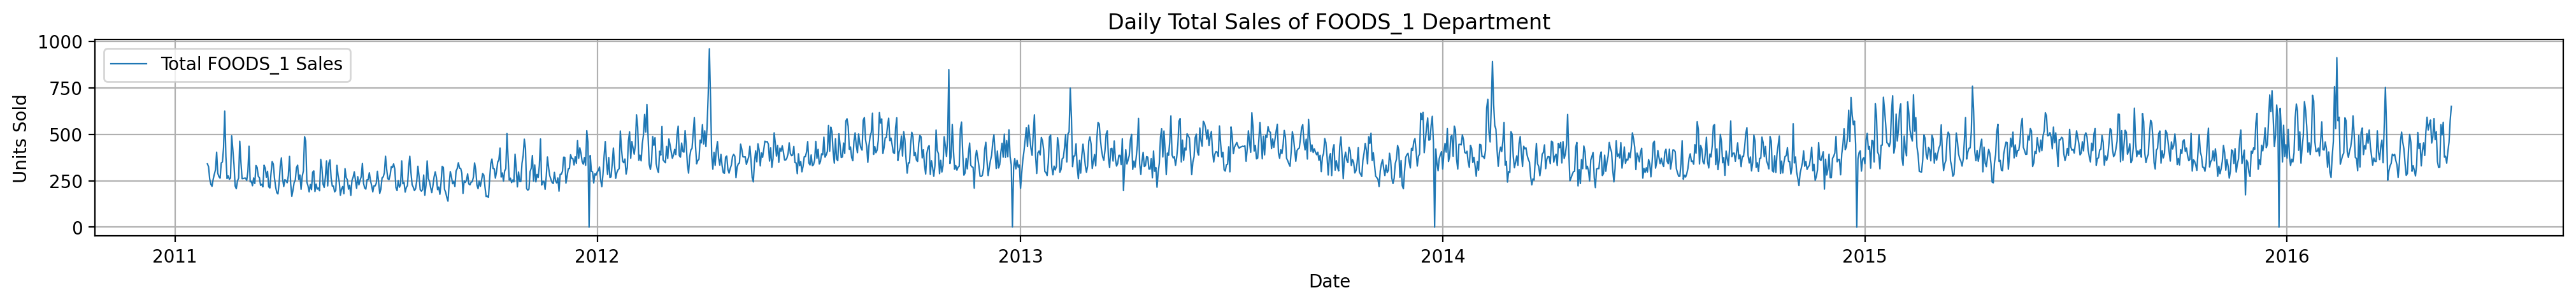

In [ ]:
# Let us plot the total daily sales of the whole FOODS_1 department
daily_total = foods1.groupby('date')['sales'].sum()

plt.figure(figsize=(25, 2), dpi=200)
plt.plot(daily_total.index, daily_total.values, label='Total FOODS_1 Sales', linewidth=0.8)
plt.title('Daily Total Sales of FOODS_1 Department')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

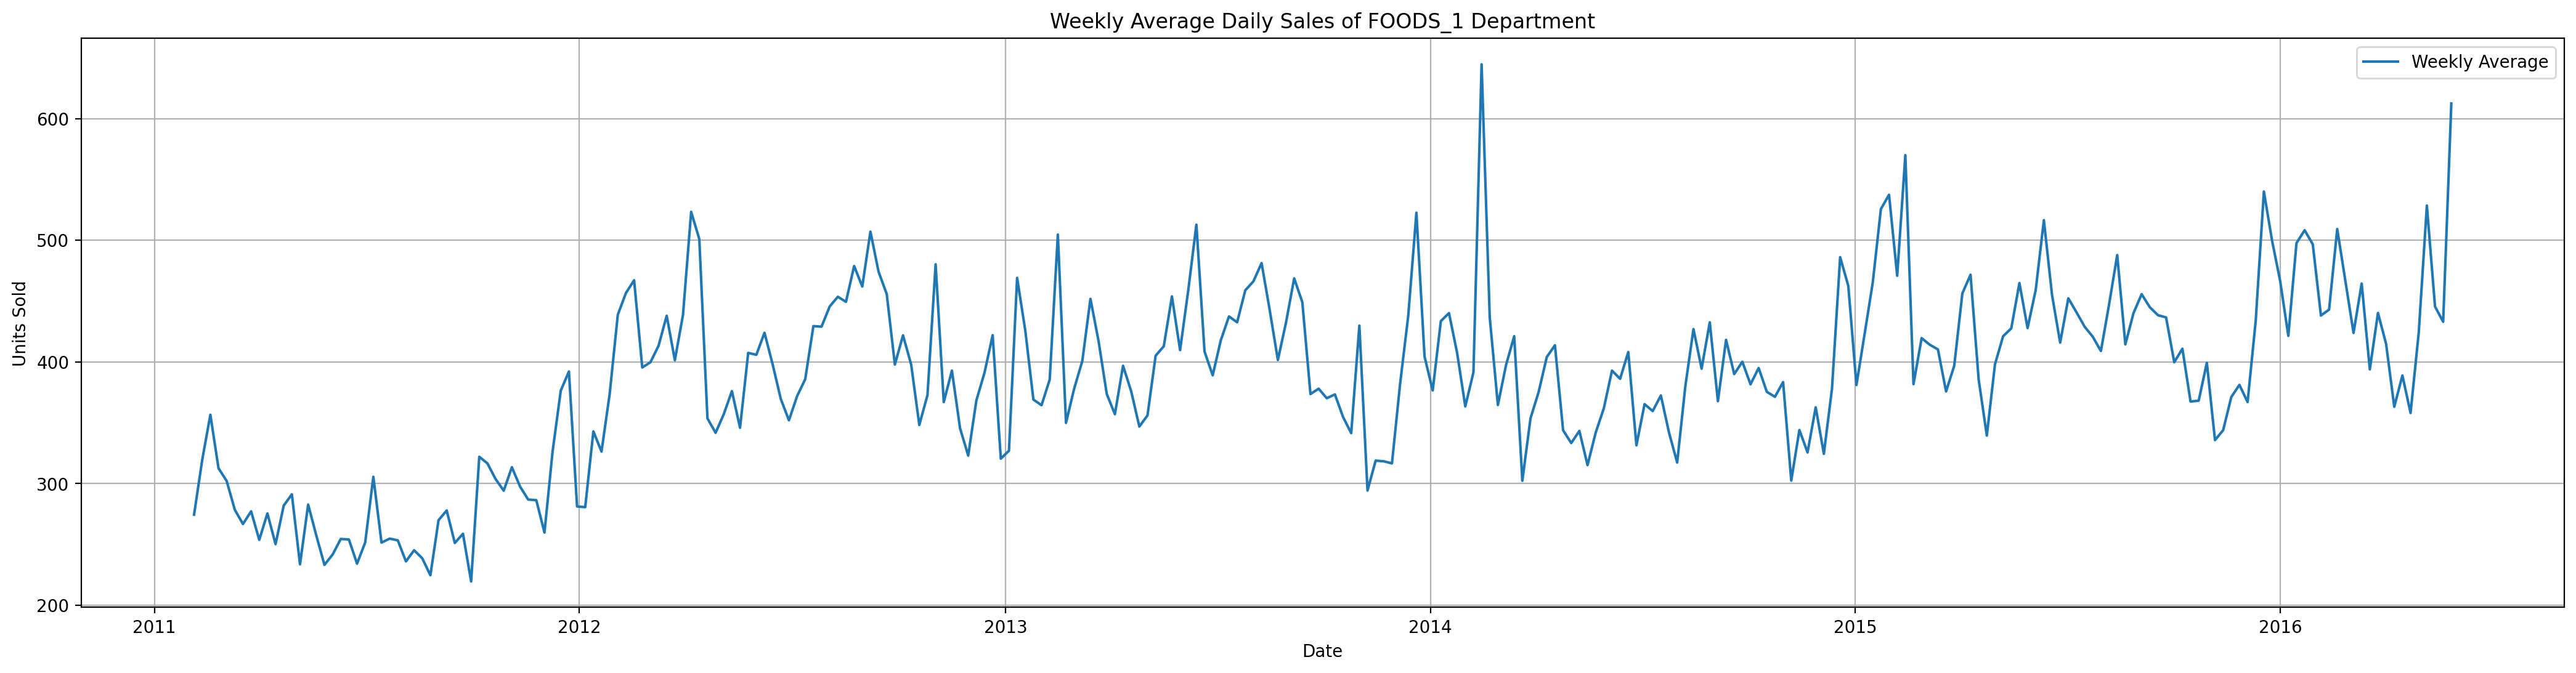

In [ ]:
# Let us also plot the weekly average so that the trend becomes more clear
weekly_total = daily_total.resample('W-FRI').mean()

plt.figure(figsize=(26, 6), dpi=200)
plt.plot(weekly_total.index, weekly_total.values, label='Weekly Average')
plt.title('Weekly Average Daily Sales of FOODS_1 Department')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

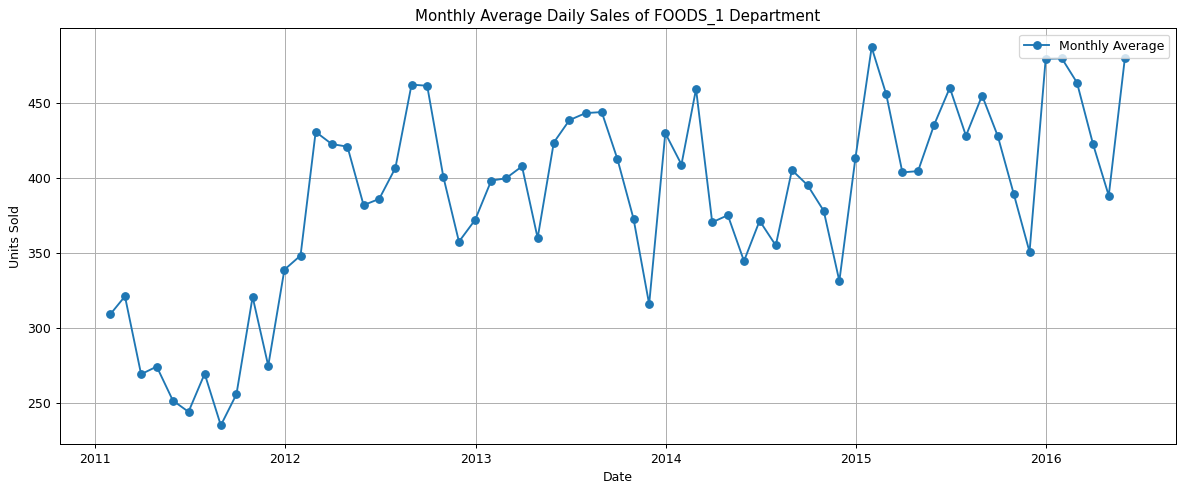

In [ ]:
# Let us also plot the monthly average so that the trend becomes more clear
monthly_total = daily_total.resample('ME').mean()

plt.figure(figsize=(16, 6), dpi=90)
plt.plot(monthly_total.index, monthly_total.values, label='Monthly Average', marker='o')
plt.title('Monthly Average Daily Sales of FOODS_1 Department')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

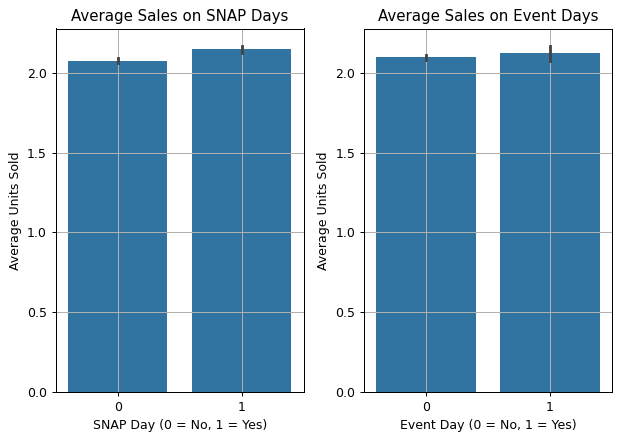

In [ ]:
# Let us see the effect of the SNAP days and the event days on our sales
plt.figure(figsize=(7, 5), dpi=90)
plt.subplot(1, 2, 1)
sns.barplot(x='snap_CA', y='sales', data=foods1)
plt.title('Average Sales on SNAP Days')
plt.xlabel('SNAP Day (0 = No, 1 = Yes)')
plt.ylabel('Average Units Sold')
plt.grid(True)

plt.subplot(1, 2, 2)
sns.barplot(x='is_event', y='sales', data=foods1)
plt.title('Average Sales on Event Days')
plt.xlabel('Event Day (0 = No, 1 = Yes)')
plt.ylabel('Average Units Sold')
plt.tight_layout()
plt.grid(True)
plt.show()

In [ ]:

foods1.to_csv('/content/m5_panel_foods1.csv', index=False)

#print("Final shape :", foods1.shape)

## Further Narrowing the Project By fixing the Global Random Seed and 100 Series Subsample

To reduce the processing time, we fix a single project random seed and draw a fixed random subsamples of 100 from the 216 FOODS_1 series.

In [ ]:
# Our global random seed for our whole project will be 42

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# here we will use the dedicated Generator in order to use it wherever an explicit RNG(Random Number Generator) is required "Kaggle Ref."
rng = np.random.default_rng(SEED)

print(f"Our global: SEED = {SEED}")


Our global: SEED = 42


In [ ]:
# let us randomly select 100 from the 216 series

N_SERIES = 100

all_items = np.sort(foods1['item_id'].unique())
print("Series available:", len(all_items))

# our reproducible random draw of N_SERIES item_ids (fixed by SEED, independent of the RNG state)
sampled_items = pd.Series(all_items).sample(n=N_SERIES, random_state=SEED).tolist()

# we are Keeping the full dataset under a separate name, then reduce the working panel to the sample
foods1_full = foods1.copy()
foods1 = foods1[foods1['item_id'].isin(sampled_items)].sort_values(['item_id', 'date']).reset_index(drop=True)

print(f"Series we selected : {foods1['item_id'].nunique()}")
print(f"Rows            : {len(foods1_full):,} (full 216)  ->  {len(foods1):,} (sample of {N_SERIES})")

# we are Saving the subsample so that a restarted kernel can reload it directly
foods1.to_csv('/content/m5_panel_foods1_sample100.csv', index=False)
print("Saved sample to /content/m5_panel_foods1_sample100.csv")

Series available: 216
Series we selected : 100
Rows            : 357,467 (full 216)  ->  162,621 (sample of 100)
Saved sample to /content/m5_panel_foods1_sample100.csv


In [ ]:
# Extracting date features
foods1['day_of_week'] = foods1['date'].dt.dayofweek
foods1['day_of_month'] = foods1['date'].dt.day
foods1['day_of_year'] = foods1['date'].dt.dayofyear
foods1['week_of_year'] = foods1['date'].dt.isocalendar().week.astype(int)

# Displying the new columns
foods1[['date', 'day_of_week', 'day_of_month', 'day_of_year', 'week_of_year']].head(10)

,date,day_of_week,day_of_month,day_of_year,week_of_year
0,2011-01-29,5,29,29,4
1,2011-01-30,6,30,30,4
2,2011-01-31,0,31,31,5
3,2011-02-01,1,1,32,5
4,2011-02-02,2,2,33,5
5,2011-02-03,3,3,34,5
6,2011-02-04,4,4,35,5
7,2011-02-05,5,5,36,5
8,2011-02-06,6,6,37,5
9,2011-02-07,0,7,38,6


In [ ]:
# Defining the RMSSE metric
def calculate_rmsse(y_true, y_pred, y_train):
    """
    Calculates the Root Mean Squared Scaled Error (RMSSE) as per M5 competition.

    Parameters:
    y_true : Actual values of the test set.
    y_pred : Predicted values for the test set.
    y_train : Training data used to calculate the scaling factor.

    Returns:
    float: The RMSSE value.
    """
    # Ensuring that y_train has minimum two elements to calculate diff
    if len(y_train) < 2:
        # If not enough training data to compute scale, return NaN
        return np.nan

    numerator = np.sqrt(mean_squared_error(y_true, y_pred))
    denominator = np.sqrt(np.mean(np.diff(y_train)**2))

    if denominator == 0:
        return np.nan # ignorring division by zero if training data has no variance

    return numerator / denominator

### Preparing Data for StatsForecast
For the statsforecast we requires unique_id for the series identifier, ds for the timestamp, and y for the target variable.

In [ ]:
# Data Preparation for Forecasting and defining the forecast horizon (h)

h = 28
last_date = foods1['date'].max()
train_end_date = last_date - pd.Timedelta(days=h)
train_df = foods1[foods1['date'] <= train_end_date].copy()
val_df = foods1[foods1['date'] > train_end_date].copy()

In [ ]:
print(f"Training data from {train_df['date'].min().date()} to {train_df['date'].max().date()}")
print(f"Validation data from {val_df['date'].min().date()} to {val_df['date'].max().date()}")
print(f"Number of unique items in training: {train_df['item_id'].nunique()}")
print(f"Number of unique items in validation: {val_df['item_id'].nunique()}")

# Dictionary to store RMSSE results for all models
rmsse_results = {}

Training data from 2011-01-29 to 2016-04-24
Validation data from 2016-04-25 to 2016-05-22
Number of unique items in training: 100
Number of unique items in validation: 100


In [ ]:
# Statistical Models (Seasonal Naive, AutoETS, AutoARIMA)

# Preparing the data for StatsForecast, renaming our columns to 'unique_id', 'ds', 'y'

sf_data_train = train_df[['item_id', 'date', 'sales']].rename(columns={'item_id': 'unique_id', 'date': 'ds', 'sales': 'y'})
sf_data_val = val_df[['item_id', 'date', 'sales']].rename(columns={'item_id': 'unique_id', 'date': 'ds', 'sales': 'y'})


SEASON_LENGTH = 7
stats_models = [
    SeasonalNaive(season_length=SEASON_LENGTH),
    AutoETS(season_length=SEASON_LENGTH),
    AutoARIMA(season_length=SEASON_LENGTH)
]

sf = StatsForecast(
    models=stats_models,
    freq='D',
    n_jobs=-1
)
# Fitting the models on the training data

sf.fit(sf_data_train)

# Generating the forecasts for the period of h days

forecast_sf = sf.predict(h=h)


In [ ]:
# Now merging the actual sales values of the h days to the forecasts of the RMSSE calculation

forecast_sf = pd.merge(forecast_sf, sf_data_val[['unique_id', 'ds', 'y']], on=['unique_id', 'ds'], how='left')
forecast_sf = forecast_sf.sort_values(by=['unique_id', 'ds']).reset_index(drop=True)

In [ ]:
# Calculate RMSSE for each StatsForecast model by aggregating across all the items

for model_name in ['SeasonalNaive', 'AutoETS', 'AutoARIMA']:
    rmsse_list = []
    for item_id in sf_data_val['unique_id'].unique():
        y_true_item = forecast_sf[forecast_sf['unique_id'] == item_id]['y'].values
        y_pred_item = forecast_sf[forecast_sf['unique_id'] == item_id][model_name].values
        y_train_item = sf_data_train[sf_data_train['unique_id'] == item_id]['y'].values

        if len(y_true_item) > 0 and len(y_pred_item) > 0 and len(y_train_item) > 1:
            rmsse_list.append(calculate_rmsse(y_true_item, y_pred_item, y_train_item))

    if rmsse_list:
        rmsse_results[model_name] = np.mean(rmsse_list)
    else:
        rmsse_results[model_name] = np.nan # If no valid RMSSE could be calculated
    print(f"RMSSE for {model_name}: {rmsse_results[model_name]:.4f}")

RMSSE for SeasonalNaive: 0.9845
RMSSE for AutoETS: 0.7572
RMSSE for AutoARIMA: 0.7443


### Feature Engineering


Let us do some engineering

In [ ]:
# ML Models Feature Engineering

def create_ml_features(df, forecast_horizon):
    df = df.copy()

    # Lag features (sales from previous days)
    df['sales_lag_7'] = df.groupby('item_id')['sales'].transform(lambda x: x.shift(7))
    df['sales_lag_14'] = df.groupby('item_id')['sales'].transform(lambda x: x.shift(14))
    df['sales_lag_28'] = df.groupby('item_id')['sales'].transform(lambda x: x.shift(28))

    # Rolling mean features (average sales over a window)
    # We shift by forecast_horizon to avoid data leakage from the future
    df['rolling_mean_7'] = df.groupby('item_id')['sales'].transform(lambda x: x.shift(forecast_horizon).rolling(7).mean())
    df['rolling_mean_28'] = df.groupby('item_id')['sales'].transform(lambda x: x.shift(forecast_horizon).rolling(28).mean())

    # Price related features
    df['price_lag_1'] = df.groupby('item_id')['sell_price'].transform(lambda x: x.shift(1))
    df['price_roll_mean_7'] = df.groupby('item_id')['sell_price'].transform(lambda x: x.shift(1).rolling(7).mean())

    # Date features i already re-extracted before but its okay for consistency and clarity i do again in one place.
    df['day_of_week'] = df['date'].dt.dayofweek
    df['day_of_month'] = df['date'].dt.day
    df['month'] = df['date'].dt.month
    df['year'] = df['date'].dt.year
    df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)
    df['day_of_year'] = df['date'].dt.dayofyear

    # New: Sine and Cosine features for day of year to capture annual seasonality
    df['day_of_year_sin'] = np.sin(2 * np.pi * df['day_of_year'] / 365)
    df['day_of_year_cos'] = np.cos(2 * np.pi * df['day_of_year'] / 365)

    # Other categorical features (ensure they are integer types for tree models)
    df['wm_yr_wk'] = df['wm_yr_wk'].astype(int)
    df['wday'] = df['wday'].astype(int)
    df['snap_CA'] = df['snap_CA'].astype(int)
    df['store_closed'] = df['store_closed'].astype(int)
    df['is_event'] = df['is_event'].astype(int)

    return df

In [ ]:
# Applying the feature engineering to the full dataset first, then we split to ensure correct lag calculations

full_ml_df = create_ml_features(foods1.sort_values(by=['item_id', 'date']), h)


In [ ]:
# Spliting the feature engineered data into training and validation sets

ml_train_df = full_ml_df[full_ml_df['date'] <= train_end_date].copy()
ml_val_df = full_ml_df[full_ml_df['date'] > train_end_date].copy()

In [ ]:
# Drop rows with NaN values introduced by lag/rolling features in the training set, these NaNs usually appear at the beginning of each series.

ml_train_df.dropna(inplace=True)

### Let us do some settings
 We need to separate the input features from the target variable. So that we can create a training and validation matrix X train and validation along with the corresponding actual sales vlues for y train and validation. The reason of doing this is to for any ML models they learn patterns from the past data and then be evaluated on the non seen data.

In [ ]:
# Define features X and target y for ML models

features = [col for col in ml_train_df.columns if col not in ['item_id', 'date', 'sales']]
X_train_ml = ml_train_df[features]
y_train_ml = ml_train_df['sales']

X_val_ml = ml_val_df[features]
y_val_ml = ml_val_df['sales'] # This contains the actuals for validation

print(f"ML training data shape: {X_train_ml.shape}")
print(f"ML validation data shape: {X_val_ml.shape}")
print(f"Number of features used: {len(features)}")


ML training data shape: (154321, 21)
ML validation data shape: (2800, 21)
Number of features used: 21


In [ ]:
# Identifying the categorical features for CatBoost

categorical_features_cols = ['wm_yr_wk', 'wday', 'month', 'year', 'snap_CA', 'store_closed', 'is_event', 'day_of_week', 'day_of_month', 'week_of_year']
categorical_features_indices = [X_train_ml.columns.get_loc(col) for col in categorical_features_cols if col in X_train_ml.columns]


In [ ]:
# Now defining the function to calculate and store RMSSE for ML models

def evaluate_ml_model(model_name, predictions, val_df_ml, train_df_ml, rmsse_results_dict):

    # make sure the predictions are not negative as we know sales cannot be negative

    predictions[predictions < 0] = 0

    rmsse_list_ml = []

    # Creating the temporary DataFrame for validation with predictions to easily group by item_id

    val_with_preds = val_df_ml.copy()
    val_with_preds['predictions'] = predictions

    for item_id in val_with_preds['item_id'].unique():
        y_true_item = val_with_preds[val_with_preds['item_id'] == item_id]['sales'].values
        y_pred_item = val_with_preds[val_with_preds['item_id'] == item_id]['predictions'].values
        y_train_item = train_df_ml[train_df_ml['item_id'] == item_id]['sales'].values

        if len(y_true_item) > 0 and len(y_pred_item) > 0 and len(y_train_item) > 1:
            rmsse_list_ml.append(calculate_rmsse(y_true_item, y_pred_item, y_train_item))

    if rmsse_list_ml:
        rmsse_results_dict[model_name] = np.mean(rmsse_list_ml)
    else:
        rmsse_results_dict[model_name] = np.nan
    print(f"RMSSE for {model_name}: {rmsse_results_dict[model_name]:.4f}")


# XGBoost Model

In [ ]:
# This denominator is fixed for the entire cross-validation process. and ensuring y_train_ml has enough data points to compute diff
if len(y_train_ml) < 2:
    rmsse_denominator_overall = 1e-9  #A small non-zero value to prevent division by zero
else:
    rmsse_denominator_overall = np.sqrt(np.mean(np.diff(y_train_ml.values)**2))

# Handling degenerate case where training data has no variance
if rmsse_denominator_overall == 0:
    print("Warning: rmsse_denominator_overall is zero. RMSSE may be ill-defined. Setting to a small epsilon.")
    rmsse_denominator_overall = 1e-9 # A small non-zero value to prevent division by zero

# Defining the custom scoring function for the make_scorer our function will receives y_true and y_pred from the cross-validation fold's test set Since make_scorer expects greater_is_better=True by default, and RMSSE is "lower is better", we return the negative RMSSE.
def rmsse_scorer_func(y_true, y_pred):
    # Ensuring predictions are non-negative, as sales cannot be negative
    y_pred = np.maximum(0, y_pred)

    numerator = np.sqrt(mean_squared_error(y_true, y_pred))
    return - (numerator / rmsse_denominator_overall)

# Create the scorer
rmsse_scorer_cv = make_scorer(rmsse_scorer_func, greater_is_better=True)

In [ ]:
#Tuning the XGBoost Model with Randomized Search Cross Validation
#Define hyperparameter search space
xgb_params = {'n_estimators': [100, 200, 300, 500, 800],'max_depth': [3, 5, 7],
              'learning_rate': [0.01, 0.05, 0.1],'subsample': [0.7, 0.8, 0.9]
}

#Base model for Randomized Search CV
xgb_model = xgb.XGBRegressor(objective='reg:squarederror',random_state=42,
                             n_jobs=-1,verbose=0)

#Randomized Search CV setup
xgb_random = RandomizedSearchCV(estimator=xgb_model,
                                param_distributions=xgb_params,n_iter=5,cv=3,
                                scoring=rmsse_scorer_cv,random_state=42,
                                n_jobs=-1,verbose=0)

# Fit tuned model
xgb_random.fit(X_train_ml, y_train_ml)

#Extract best model
best_xgb_model = xgb_random.best_estimator_

# Predict
xgb_preds = best_xgb_model.predict(X_val_ml)

# Evaluate
evaluate_ml_model('XGBoost',xgb_preds,ml_val_df,ml_train_df,rmsse_results,)

RMSSE for XGBoost: 0.7515


# LightGBM Model

In [ ]:
#Tuning the LightGBM Model with Randomized Search Cross Validation
# Hyperparameter search space
lgb_params = {'n_estimators': [100, 200, 300, 500, 800],'max_depth': [5, 7, 9],
              'learning_rate': [0.01, 0.05, 0.1],'subsample': [0.7, 0.8, 0.9]}

# Base LightGBM model
lgb_model = lgb.LGBMRegressor(objective='regression',random_state=42,n_jobs=-1,verbose=-1)

# Randomized Search CV setup
lgb_random = RandomizedSearchCV(estimator=lgb_model,param_distributions=lgb_params,n_iter=5,cv=3,
                                scoring=rmsse_scorer_cv,random_state=42,n_jobs=-1,verbose=0)

# Fit tuned model
lgb_random.fit(X_train_ml, y_train_ml)

# Extract best model
best_lgb_model = lgb_random.best_estimator_

# Predict
lgb_preds = best_lgb_model.predict(X_val_ml)

# Evaluate
evaluate_ml_model('LightGBM',lgb_preds,ml_val_df,ml_train_df,rmsse_results)


RMSSE for LightGBM: 0.7621


# CatBoost Model

In [ ]:
#Tuning the CatBoost Model with Randomized Search Cross Validation
# Hyperparameter searching
cat_params = {'iterations': [100, 200, 300],'depth': [ 6, 8, 10],'learning_rate': [0.01, 0.05, 0.1],'l2_leaf_reg': [1, 3, 5]}

# initial CatBoost model
cat_model = CatBoostRegressor(random_seed=42,verbose=0)

# RandomizedSearchCV setup
cat_random = RandomizedSearchCV(estimator=cat_model,param_distributions=cat_params,n_iter=5,cv=3,scoring=rmsse_scorer_cv,random_state=42,n_jobs=-1,verbose=0)

# Fit tuned model
cat_random.fit(X_train_ml,y_train_ml,cat_features=categorical_features_indices)

# Extracting best model
best_cat_model = cat_random.best_estimator_

# Predicting
cat_preds = best_cat_model.predict(X_val_ml)

# Evaluating
evaluate_ml_model('CatBoost',cat_preds,ml_val_df,ml_train_df,rmsse_results)

RMSSE for CatBoost: 0.7860


# Comparison and Conclusion

The below RMSSE output is for h = 28 days

In [ ]:
# Printing all the RMSSE results in the sorted way

for model, rmsse_val in sorted(rmsse_results.items(), key=lambda item: item[1] if not np.isnan(item[1]) else float('inf')):
    if not np.isnan(rmsse_val):
        print(f"  {model:<15}: {rmsse_val:.4f}")
    else:
        print(f"  {model:<15}: Not applicable (e.g., insufficient training data for scaling)")

# Determining the model with the lowest RMSSE and filtering out the NaN values before finding the minimum

comparable_results = {k: v for k, v in rmsse_results.items() if not np.isnan(v)}

if comparable_results:
    best_model = min(comparable_results, key=comparable_results.get)
    print(f"\nThe model with the lowest RMSSE is: {best_model} with an RMSSE of {comparable_results[best_model]:.4f}.")
else:
    print("\nCould not determine a best model as no valid RMSSE values were calculated.")


  AutoARIMA      : 0.7443
  XGBoost        : 0.7515
  AutoETS        : 0.7572
  LightGBM       : 0.7621
  CatBoost       : 0.7860
  SeasonalNaive  : 0.9845

The model with the lowest RMSSE is: AutoARIMA with an RMSSE of 0.7443.


# Multi-Horizon Forecasting Accuracy Analysis

To analyze that how forecasting accuracy changes with the horizon, we will re-evaluate all models for week 1 (7 days), week 2 (14 days), and week 4 (28 days) ahead forecasts. The Root Mean Squared Scaled Error (RMSSE) will be used as the evaluation metric as a standard.

In [ ]:
forecast_horizons_weeks = [1, 2, 4]
forecast_horizons_days = [w * 7 for w in forecast_horizons_weeks]
all_rmsse_results = {} # Storing mean RMSSE for the summary table
all_detailed_rmsse_lists = {} # Storing the lists of RMSSE for statistical tests

for h_current in forecast_horizons_days:
    print(f"\n solvingg models for a forecast horizon of {h_current} days (Week {h_current/7:.0f})")

    mean_rmsse_for_current_h = {} # Storing mean RMSSE for this specific horizon
    detailed_rmsse_for_current_h = {} # Storing lists of RMSSEs for this specific horizon

    # Now data Preparation for the current horizon

    last_date = foods1['date'].max()
    train_end_date = last_date - pd.Timedelta(days=28)

    train_df = foods1[foods1['date'] <= train_end_date].copy()
    val_df = foods1[foods1['date'] > train_end_date].copy()

    print(f"  Training data from {train_df['date'].min().date()} to {train_df['date'].max().date()}")
    print(f"  Validation data from {val_df['date'].min().date()} to {val_df['date'].max().date()}")

    #Statistical Models

    print("Running forecast Models")
    sf_data_train = train_df[['item_id', 'date', 'sales']].rename(columns={'item_id': 'unique_id', 'date': 'ds', 'sales': 'y'})
    sf_data_val = val_df[['item_id', 'date', 'sales']].rename(columns={'item_id': 'unique_id', 'date': 'ds', 'sales': 'y'})

    SEASON_LENGTH = 7
    stats_models_list = [
        SeasonalNaive(season_length=SEASON_LENGTH),
        AutoETS(season_length=SEASON_LENGTH),
        AutoARIMA(season_length=SEASON_LENGTH)
    ]
    sf = StatsForecast(models=stats_models_list, freq='D', n_jobs=-1)
    sf.fit(sf_data_train)
    forecast_sf = sf.predict(h=h_current)

    forecast_sf = pd.merge(forecast_sf, sf_data_val[['unique_id', 'ds', 'y']], on=['unique_id', 'ds'], how='left')
    forecast_sf = forecast_sf.sort_values(by=['unique_id', 'ds']).reset_index(drop=True)

    for model_name in ['SeasonalNaive', 'AutoETS', 'AutoARIMA']:
        rmsse_list = []
        for item_id in sf_data_val['unique_id'].unique():
            y_true_item = forecast_sf[forecast_sf['unique_id'] == item_id]['y'].values
            y_pred_item = forecast_sf[forecast_sf['unique_id'] == item_id][model_name].values
            y_train_item = sf_data_train[sf_data_train['unique_id'] == item_id]['y'].values
            if len(y_true_item) > 0 and len(y_pred_item) > 0 and len(y_train_item) > 1:
                rmsse_list.append(calculate_rmsse(y_true_item, y_pred_item, y_train_item))

        if rmsse_list:
            mean_rmsse_for_current_h[model_name] = np.mean(rmsse_list)
            detailed_rmsse_for_current_h[model_name] = rmsse_list
        else:
            mean_rmsse_for_current_h[model_name] = np.nan
            detailed_rmsse_for_current_h[model_name] = [] # Store empty list if no RMSSEs
        print(f"    RMSSE for {model_name:<12}: {mean_rmsse_for_current_h[model_name]:.4f}")

    # ML Models Feature Engineering for current horizon

    full_ml_df = create_ml_features(foods1.sort_values(by=['item_id', 'date']), h_current)
    ml_train_df = full_ml_df[full_ml_df['date'] <= train_end_date].copy()
    ml_val_df = full_ml_df[full_ml_df['date'] > train_end_date].copy()
    ml_train_df.dropna(inplace=True)

    # features list
    features = [col for col in ml_train_df.columns if col not in ['item_id', 'date', 'sales']]
    X_train_ml = ml_train_df[features]
    y_train_ml = ml_train_df['sales']
    X_val_ml = ml_val_df[features]
    y_val_ml = ml_val_df['sales']

    # categorical_features_cols
    categorical_features_cols = ['wm_yr_wk', 'wday', 'month', 'year', 'snap_CA', 'store_closed', 'is_event', 'day_of_week', 'day_of_month', 'week_of_year']

    # Ensuring the categorical_features_indices is derived from X_train_ml columns for consistency.
    categorical_features_indices = [X_train_ml.columns.get_loc(col) for col in categorical_features_cols if col in X_train_ml.columns]

    # function to calculate and store RMSSE for ML models

    def evaluate_ml_model_and_store_lists(model_name, predictions, val_df_ml, train_df_ml, mean_rmsse_dict, detailed_rmsse_dict):

        # Ensuring the predictions are non-negative as sales cannot be negative

        predictions[predictions < 0] = 0

        rmsse_list_ml = []
        # Creating a temporary DataFrame for validation with predictions to easily group by item_id
        val_with_preds = val_df_ml.copy()
        val_with_preds['predictions'] = predictions

        for item_id in val_with_preds['item_id'].unique():
            y_true_item = val_with_preds[val_with_preds['item_id'] == item_id]['sales'].values
            y_pred_item = val_with_preds[val_with_preds['item_id'] == item_id]['predictions'].values
            y_train_item = train_df_ml[train_df_ml['item_id'] == item_id]['sales'].values

            if len(y_true_item) > 0 and len(y_pred_item) > 0 and len(y_train_item) > 1:
                rmsse_list_ml.append(calculate_rmsse(y_true_item, y_pred_item, y_train_item))

        if rmsse_list_ml:
            mean_rmsse_dict[model_name] = np.mean(rmsse_list_ml)
            detailed_rmsse_dict[model_name] = rmsse_list_ml
        else:
            mean_rmsse_dict[model_name] = np.nan
            detailed_rmsse_dict[model_name] = [] # Store empty list if no RMSSEs
        print(f"    RMSSE for {model_name:<12}: {mean_rmsse_dict[model_name]:.4f}")

    # Tuning XGBoost Model with Randomized Search CV
    xgb_params = {
        'n_estimators': [100, 200, 300, 500, 800],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.7, 0.8, 0.9]
    }
    xgb_model_base = xgb.XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1, verbose=0)
    xgb_random = RandomizedSearchCV(estimator=xgb_model_base, param_distributions=xgb_params,
                                    n_iter=5, cv=3, scoring=rmsse_scorer_cv, random_state=42,
                                    n_jobs=-1, verbose=0)
    xgb_random.fit(X_train_ml, y_train_ml)
    best_xgb_model = xgb_random.best_estimator_
    xgb_preds = best_xgb_model.predict(X_val_ml)
    evaluate_ml_model_and_store_lists('XGBoost', xgb_preds, ml_val_df, ml_train_df, mean_rmsse_for_current_h, detailed_rmsse_for_current_h)

    # Tuning LightGBM Model with Randomized Search CV
    lgb_params = {
        'n_estimators': [100, 200, 300, 500, 800],
        'max_depth': [5, 7, 9],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.7, 0.8, 0.9]
    }
    lgb_model_base = lgb.LGBMRegressor(objective='regression', random_state=42, n_jobs=-1, verbose=-1)
    lgb_random = RandomizedSearchCV(estimator=lgb_model_base, param_distributions=lgb_params,
                                    n_iter=5, cv=3, scoring=rmsse_scorer_cv, random_state=42,
                                    n_jobs=-1, verbose=0)
    lgb_random.fit(X_train_ml, y_train_ml)
    best_lgb_model = lgb_random.best_estimator_
    lgb_preds = best_lgb_model.predict(X_val_ml)
    evaluate_ml_model_and_store_lists('LightGBM', lgb_preds, ml_val_df, ml_train_df, mean_rmsse_for_current_h, detailed_rmsse_for_current_h)

    # Tuning CatBoost Model with Randomized Search CV")
    cat_params = {
        'iterations': [100, 200, 300],
        'depth': [6, 8, 10],
        'learning_rate': [0.01, 0.05, 0.1],
        'l2_leaf_reg': [1, 3, 5]
    }
    cat_model_base = CatBoostRegressor(random_seed=42, verbose=0)
    cat_random = RandomizedSearchCV(estimator=cat_model_base, param_distributions=cat_params,
                                    n_iter=5, cv=3, scoring=rmsse_scorer_cv, random_state=42,
                                    n_jobs=-1, verbose=0)
    cat_random.fit(X_train_ml, y_train_ml, cat_features=categorical_features_indices)
    best_cat_model = cat_random.best_estimator_
    cat_preds = best_cat_model.predict(X_val_ml)
    evaluate_ml_model_and_store_lists('CatBoost', cat_preds, ml_val_df, ml_train_df, mean_rmsse_for_current_h, detailed_rmsse_for_current_h)

    all_rmsse_results[f'{h_current} days'] = mean_rmsse_for_current_h
    all_detailed_rmsse_lists[f'{h_current} days'] = detailed_rmsse_for_current_h


 solvingg models for a forecast horizon of 7 days (Week 1)
  Training data from 2011-01-29 to 2016-04-24
  Validation data from 2016-04-25 to 2016-05-22
Running our Statistical Traditional Models
    RMSSE for SeasonalNaive: 0.9033
    RMSSE for AutoETS     : 0.6792
    RMSSE for AutoARIMA   : 0.6671
    RMSSE for XGBoost     : 0.7448
    RMSSE for LightGBM    : 0.7488
    RMSSE for CatBoost    : 0.7585

 solvingg models for a forecast horizon of 14 days (Week 2)
  Training data from 2011-01-29 to 2016-04-24
  Validation data from 2016-04-25 to 2016-05-22
Running our Statistical Traditional Models
    RMSSE for SeasonalNaive: 0.9652
    RMSSE for AutoETS     : 0.7309
    RMSSE for AutoARIMA   : 0.7184
    RMSSE for XGBoost     : 0.7495
    RMSSE for LightGBM    : 0.7610
    RMSSE for CatBoost    : 0.7561

 solvingg models for a forecast horizon of 28 days (Week 4)
  Training data from 2011-01-29 to 2016-04-24
  Validation data from 2016-04-25 to 2016-05-22
Running our Statistical Trad

In [ ]:
print("\n Multiple Horizon Models Comparison (Average RMSSE across all items)")
rmsse_df = pd.DataFrame(all_rmsse_results).T # Transpose to have horizons as index
display(rmsse_df)

print("\n Our Best Model on different Horizon")
for horizon, results in all_rmsse_results.items():
    comparable = {k: v for k, v in results.items() if not np.isnan(v)}
    if comparable:
        best_model_h = min(comparable, key=comparable.get)
        print(f"  Horizon {horizon:<10}: {best_model_h:<12} (RMSSE: {comparable[best_model_h]:.4f})")
    else:
        print(f"  Horizon {horizon}: No valid models.")


 Multiple Horizon Models Comparison (Average RMSSE across all items)


,SeasonalNaive,AutoETS,AutoARIMA,XGBoost,LightGBM,CatBoost
7 days,0.903329,0.679242,0.667061,0.744773,0.748827,0.758531
14 days,0.965191,0.730946,0.718369,0.749533,0.760993,0.756065
28 days,0.984527,0.757224,0.744318,0.751469,0.762100,0.785975



 Our Best Model on different Horizon
  Horizon 7 days    : AutoARIMA    (RMSSE: 0.6671)
  Horizon 14 days   : AutoARIMA    (RMSSE: 0.7184)
  Horizon 28 days   : AutoARIMA    (RMSSE: 0.7443)


### Note:
for 7 days Horizon: Auto-ARIMA, Auto-ETS, XGBoost, LightGBM, CatBoost, Seasonal Naive.

For 14 days Horizon: Auto-ARIMA, Auto-ETS, XGBoost, CatBoost, LightGBM,  Seasonal Naive.

For 28 days Horizon: Auto-ARIMA, XGBoost, Auto-ETS, LightGBM, CatBoost, Seasonal Naive.

# Friedman Test and the Nemenyi post-hoc procedure

Now we will use the friedman test in order to compare the performance of all the models measured by the RMSSE across all the items_id for every forecast horizon. Our null hypothesis in models is there is no difference in the median performance, and in case friedman tests shows that there is a significant difference then we will apply the Nemenyi post hoc test. Where we will perform all pairwise comparisons between the models to check which pairs have the statsitical significant difference.

In [ ]:
for horizon, detailed_rmsse_data in all_detailed_rmsse_lists.items():
    print(f"\n Solving all the models for statistical significance for the {horizon} (Friedman Test)")

    # Preparing the data for Friedman test
    # The Friedman test expects multiple 1-D arrays, one for each model and each array contains the RMSSE values for that model across all items.
    model_rmsse_lists = []
    model_names_friedman = []

    # First collecting the RMSSE lists for all models for the current horizon and filtering out the models with NaN RMSSE values from the average RMSSE results
    # which ensures that only models with valid data are included in the statistical tests plus checking the if all_rmsse_results is available and contains the current horizon

    if 'all_rmsse_results' in globals() and horizon in all_rmsse_results:
        valid_models_for_horizon = {k: v for k, v in all_rmsse_results[horizon].items() if not np.isnan(v)}
    else:
        print(f"  Warning: all_rmsse_results or horizon {horizon} not found. Proceeding with available detailed data.")
        valid_models_for_horizon = {k: None for k in detailed_rmsse_data.keys()} # Assume all are valid if average not available

    for model_name in sorted(detailed_rmsse_data.keys()): # Sort for consistent order
        if model_name in valid_models_for_horizon: # Only include models that has a valid average RMSSE
            rmsse_list = detailed_rmsse_data[model_name]

            # Filter out any NaN RMSSE values from the individuals lists
            rmsse_list = [x for x in rmsse_list if not np.isnan(x) and not np.isinf(x)]
            if len(rmsse_list) > 1: # Only include models with sufficient data
                model_rmsse_lists.append(rmsse_list)
                model_names_friedman.append(model_name)

    if len(model_rmsse_lists) >= 2: # Friedman test requires at least two groups

        # Ensuring that all lists are of the same length (number of items) for the Friedman test or not

        min_items_len = min(len(lst) for lst in model_rmsse_lists)
        model_rmsse_lists_aligned = [lst[:min_items_len] for lst in model_rmsse_lists]

        # Double-check if after alignment, there is still enough data points
        if min_items_len < 2: # Friedman needs at least 2 observations items per group
            print(f"  Not enough individual RMSSE observations (items) per model after alignment to perform Friedman test for {horizon}. (Min length: {min_items_len})")
            continue # Skipping to the next horizon

        # Checking if there's any variance within the samples, otherwise friedmanchisquare might return NaN p-value
        # For Friedman test, it's more about ranks, but constant values might cause issues. If all values are identical for all models across all items, p-value might be 1, or statistic 0.
        try:
            friedman_statistic, friedman_p_value = stats.friedmanchisquare(*model_rmsse_lists_aligned)
        except ValueError as e:
            print(f"  Could not perform Friedman test for {horizon} due to: {e}")
            print(f"  Lengths of lists: {[len(lst) for lst in model_rmsse_lists_aligned]}")
            continue


        print(f"  Friedman test statistic = {friedman_statistic:.4f}, p-value = {friedman_p_value:.5f}")

        alpha = 0.05
        if friedman_p_value < alpha:
            print(f"  There is significant differences found among the model performances for {horizon} (p < {alpha}). So we will proceeding with Nemenyi post-hoc test.")

            # Preparing data for Nemenyi post-hoc test
            data_for_nemenyi = np.array(model_rmsse_lists_aligned).T # Transpose to get (items x models)

            # Ensure no NaNs or Infs in data_for_nemenyi, which can cause issues with scikit-posthocs
            if np.any(np.isnan(data_for_nemenyi)) or np.any(np.isinf(data_for_nemenyi)):
                print(f"  Skipping Nemenyi post-hoc test for {horizon} due to NaN or Inf values in prepared data.")
            else:
                nemenyi_results = sp.posthoc_nemenyi_friedman(data_for_nemenyi)
                # Renaming the columns and index for the better readability
                nemenyi_results.columns = model_names_friedman
                nemenyi_results.index = model_names_friedman

                print(" Nemenyi Post-Hoc Test result p-values")
                display(nemenyi_results.round(5))

                # Highlighting significant differences
                significant_pairs = []
                for i in range(len(model_names_friedman)):
                    for j in range(i + 1, len(model_names_friedman)):
                        if nemenyi_results.iloc[i, j] < alpha:
                            significant_pairs.append(f"    - {model_names_friedman[i]} vs {model_names_friedman[j]} (p={nemenyi_results.iloc[i, j]:.3f})")
                if significant_pairs:
                    print("  Statistically significant pairwise differences (p < 0.05):")
                    for pair in significant_pairs:
                        print(pair)
                else:
                    print("  No statistically significant pairwise differences found among the models.")

        else:
            print(f"  Output Result: No statistically significant differences found among model performances for the {horizon} (p >= {alpha}).")
    else:
        print(f"  Not enough models with valid RMSSE data to perform Friedman test for the {horizon}.")


 Solving all the models for statistical significance for the 7 days (Friedman Test)
  Friedman test statistic = 61.7143, p-value = 0.00000
  There is significant differences found among the model performances for 7 days (p < 0.05). So we will proceeding with Nemenyi post-hoc test.
 Nemenyi Post-Hoc Test result p-values


,AutoARIMA,AutoETS,CatBoost,LightGBM,SeasonalNaive,XGBoost
AutoARIMA,1.00000,0.99760,0.02381,0.04687,0.00000,0.43217
AutoETS,0.99760,1.00000,0.08655,0.14957,0.00000,0.72805
CatBoost,0.02381,0.08655,1.00000,0.99992,0.00187,0.81341
LightGBM,0.04687,0.14957,0.99992,1.00000,0.00075,0.91127
SeasonalNaive,0.00000,0.00000,0.00187,0.00075,1.00000,0.00001
XGBoost,0.43217,0.72805,0.81341,0.91127,0.00001,1.00000


  Statistically significant pairwise differences (p < 0.05):
    - AutoARIMA vs CatBoost (p=0.024)
    - AutoARIMA vs LightGBM (p=0.047)
    - AutoARIMA vs SeasonalNaive (p=0.000)
    - AutoETS vs SeasonalNaive (p=0.000)
    - CatBoost vs SeasonalNaive (p=0.002)
    - LightGBM vs SeasonalNaive (p=0.001)
    - SeasonalNaive vs XGBoost (p=0.000)

 Solving all the models for statistical significance for the 14 days (Friedman Test)
  Friedman test statistic = 99.0457, p-value = 0.00000
  There is significant differences found among the model performances for 14 days (p < 0.05). So we will proceeding with Nemenyi post-hoc test.
 Nemenyi Post-Hoc Test result p-values


,AutoARIMA,AutoETS,CatBoost,LightGBM,SeasonalNaive,XGBoost
AutoARIMA,1.00000,0.98777,0.68095,0.89779,0.0,0.99900
AutoETS,0.98777,1.00000,0.96174,0.99842,0.0,0.91127
CatBoost,0.68095,0.96174,1.00000,0.99842,0.0,0.43217
LightGBM,0.89779,0.99842,0.99842,1.00000,0.0,0.70479
SeasonalNaive,0.00000,0.00000,0.00000,0.00000,1.0,0.00000
XGBoost,0.99900,0.91127,0.43217,0.70479,0.0,1.00000


  Statistically significant pairwise differences (p < 0.05):
    - AutoARIMA vs SeasonalNaive (p=0.000)
    - AutoETS vs SeasonalNaive (p=0.000)
    - CatBoost vs SeasonalNaive (p=0.000)
    - LightGBM vs SeasonalNaive (p=0.000)
    - SeasonalNaive vs XGBoost (p=0.000)

 Solving all the models for statistical significance for the 28 days (Friedman Test)
  Friedman test statistic = 176.4000, p-value = 0.00000
  There is significant differences found among the model performances for 28 days (p < 0.05). So we will proceeding with Nemenyi post-hoc test.
 Nemenyi Post-Hoc Test result p-values


,AutoARIMA,AutoETS,CatBoost,LightGBM,SeasonalNaive,XGBoost
AutoARIMA,1.00000,0.93478,0.01658,0.07106,0.0,0.96868
AutoETS,0.93478,1.00000,0.20733,0.48108,0.0,0.99999
CatBoost,0.01658,0.20733,1.00000,0.99649,0.0,0.14957
LightGBM,0.07106,0.48108,0.99649,1.00000,0.0,0.38508
SeasonalNaive,0.00000,0.00000,0.00000,0.00000,1.0,0.00000
XGBoost,0.96868,0.99999,0.14957,0.38508,0.0,1.00000


  Statistically significant pairwise differences (p < 0.05):
    - AutoARIMA vs CatBoost (p=0.017)
    - AutoARIMA vs SeasonalNaive (p=0.000)
    - AutoETS vs SeasonalNaive (p=0.000)
    - CatBoost vs SeasonalNaive (p=0.000)
    - LightGBM vs SeasonalNaive (p=0.000)
    - SeasonalNaive vs XGBoost (p=0.000)


## RMSSE Trends Across Forecasting Horizons for Each Model

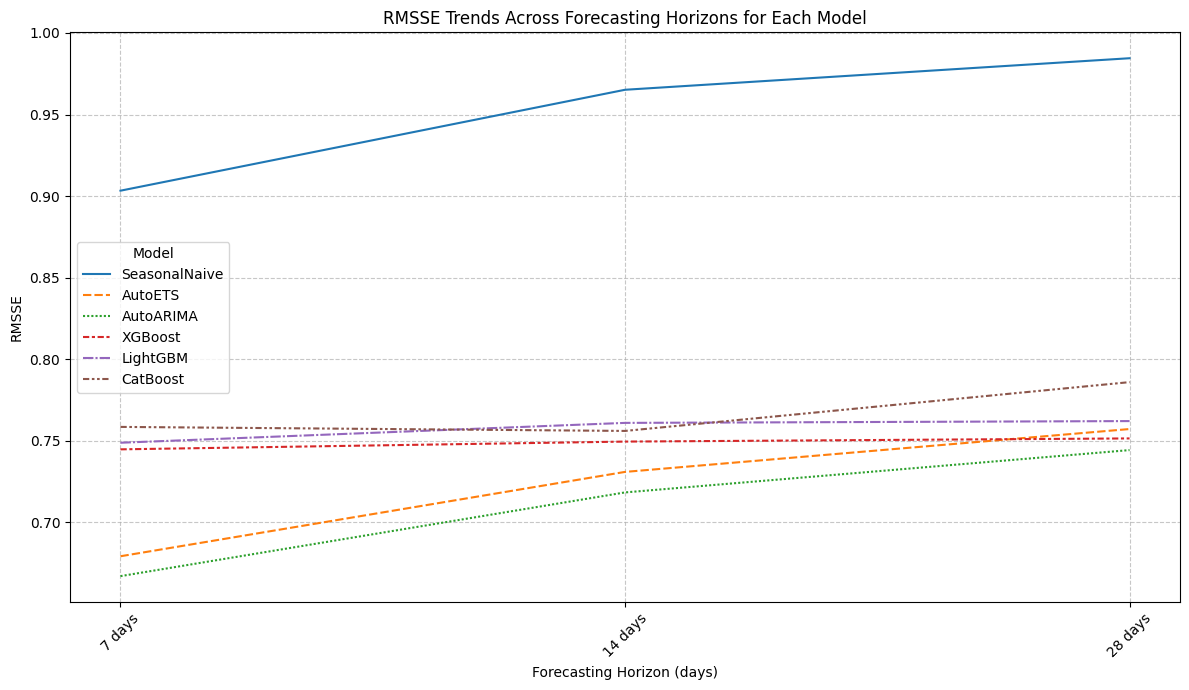

In [ ]:
plt.figure(figsize=(12, 7))
sns.lineplot(data=rmsse_df)
plt.title('RMSSE Trends Across Forecasting Horizons for Each Model')
plt.xlabel('Forecasting Horizon (days)')
plt.ylabel('RMSSE')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

# New Extra Addition And Analysis in our work

### Aggregating the daily panel to weekly

In [ ]:
# As we know that the Walmart week (wm_yr_wk) is fixed from Saturday to Friday a 7days of block, also the freq. on which sell_price is defined, so we will aggregate on it.
weekly = (foods1
          .groupby(['item_id', 'wm_yr_wk'], as_index=False)
          .agg(sales        = ('sales', 'sum'),
               sell_price   = ('sell_price', 'mean'),
               snap_days    = ('snap_CA', 'sum'),
               event_days   = ('is_event', 'sum'),
               store_closed = ('store_closed', 'max'),
               week_start   = ('date', 'min'),
               n_days       = ('sales', 'size')))

# Keep only complete 7 day weeks so weekly totals are comparable across the weeks
# plus we dropping which are not 7 in total like the last week in our dataset haveing two days

weekly = weekly[weekly['n_days'] == 7].drop(columns='n_days').copy()

# Calendar features
weekly['month']        = weekly['week_start'].dt.month
weekly['year']         = weekly['week_start'].dt.year
weekly['week_of_year'] = weekly['week_start'].dt.isocalendar().week.astype(int)

# Integer code for each product so the single global model can tell the series apart
weekly['item_code'] = weekly['item_id'].astype('category').cat.codes

weekly = weekly.sort_values(['item_id', 'week_start']).reset_index(drop=True)

wk_counts = weekly.groupby('item_id').size()
print("Weekly panel shape :", weekly.shape)
print("Number of series   :", weekly['item_id'].nunique())
print("Weeks per series   : min %d | median %d | max %d"
      % (wk_counts.min(), int(wk_counts.median()), wk_counts.max()))
print("Week starts are all Saturdays:", bool((weekly['week_start'].dt.dayofweek == 5).all()))
SEASON_WEEKS = 52
weekly.head()

Weekly panel shape : (23203, 12)
Number of series   : 100
Weeks per series   : min 76 | median 277 | max 277
Week starts are all Saturdays: True


,item_id,wm_yr_wk,sales,sell_price,snap_days,event_days,store_closed,week_start,month,year,week_of_year,item_code
0,FOODS_1_003,11101,9,2.88,4,0,0,2011-01-29,1,2011,4,0
1,FOODS_1_003,11102,6,2.88,6,1,0,2011-02-05,2,2011,5,0
2,FOODS_1_003,11103,14,2.88,0,1,0,2011-02-12,2,2011,6,0
3,FOODS_1_003,11104,9,2.88,0,1,0,2011-02-19,2,2011,7,0
4,FOODS_1_003,11105,6,2.88,4,0,0,2011-02-26,2,2011,8,0


In [ ]:
# weekly features, rolling stats shifted by the horizon h
def create_weekly_ml_features(df, h_weeks):
    df = df.sort_values(['item_id', 'week_start']).copy()
    g = df.groupby('item_id')['sales']
    for L in [1, 2, 4, SEASON_WEEKS]:      # weekly sales lags
        df[f'lag_{L}'] = g.shift(L)
    for W in [1, 4]:                   # rolling means, shifted by h
        df[f'roll_mean_{W}'] = g.transform(lambda s: s.shift(h_weeks).rolling(W).mean())
    df['price_lag_1']  = df.groupby('item_id')['sell_price'].shift(1)
    df['price_roll_4'] = df.groupby('item_id')['sell_price'].transform(lambda s: s.shift(1).rolling(4).mean())
    return df

WEEKLY_FEATURES = ['lag_1', 'lag_2', 'lag_4', f'lag_{SEASON_WEEKS}',
                   'roll_mean_1', 'roll_mean_4', 'price_lag_1', 'price_roll_4',
                   'sell_price', 'snap_days', 'event_days', 'store_closed',
                   'month', 'year', 'week_of_year', 'item_code']
CAT_FEATURES = ['item_code', 'month', 'year', 'week_of_year', 'store_closed']


In [ ]:
def wrmsse_weights(train_weekly):
    last4 = train_weekly.sort_values('week_start').groupby('item_id').tail(4)
    dollars = (last4['sales'] * last4['sell_price']).groupby(last4['item_id']).sum()
    return dollars / dollars.sum() # Series indexed by item_id, sums to 1


### Using the above calculated weights to calculate the final WRMSSE score

In [ ]:
def weighted_rmsse(rmsse_by_item, weights):
    common = rmsse_by_item.index.intersection(weights.index)
    w = weights.loc[common] / weights.loc[common].sum()
    return float((rmsse_by_item.loc[common] * w).sum())

## Weekly Multi-Horizon Forecasting with RMSSE

In [ ]:
weekly_forecast_horizons_weeks = [1, 2, 4]
weekly_forecast_horizons_days = [w * 7 for w in weekly_forecast_horizons_weeks]

# Dictionaries to store results of all the ML and Statistical models.
all_weekly_rmsse_results = {}
all_weekly_detailed_rmsse_lists = {}

# creating the function to calculate and store RMSSE for ML models
def evaluate_weekly_ml_model_and_store_metrics(model_name, predictions, val_df_ml, train_df_ml, mean_rmsse_dict, detailed_rmsse_dict):

    predictions[predictions < 0] = 0

    rmsse_list_ml = []

    val_with_preds = val_df_ml.copy()
    val_with_preds['predictions'] = predictions

    for item_id in val_with_preds['item_id'].unique():
        y_true_item = val_with_preds[val_with_preds['item_id'] == item_id]['sales'].values
        y_pred_item = val_with_preds[val_with_preds['item_id'] == item_id]['predictions'].values
        y_train_item = train_df_ml[train_df_ml['item_id'] == item_id]['sales'].values

        if len(y_true_item) > 0 and len(y_pred_item) > 0 and len(y_train_item) > 1:
            rmsse_val = calculate_rmsse(y_true_item, y_pred_item, y_train_item)
            rmsse_list_ml.append(rmsse_val)

    if rmsse_list_ml:
        mean_rmsse_dict[model_name] = np.mean(rmsse_list_ml)
        detailed_rmsse_dict[model_name] = rmsse_list_ml
    else:
        mean_rmsse_dict[model_name] = np.nan
        detailed_rmsse_dict[model_name] = []

    print(f"    {model_name:<12} - RMSSE: {mean_rmsse_dict[model_name]:.4f}")

In [ ]:
# creating the function to calculate and store RMSSE for StatsForecast models
def evaluate_weekly_stats_model_and_store_metrics(model_name, predictions_df, sf_val_df, sf_train_df, mean_rmsse_dict, detailed_rmsse_dict):
    rmsse_list_sf = []

    for item_id in sf_val_df['unique_id'].unique():
        # Ensure predictions_df contains the predicted column for the given model name
        if model_name in predictions_df.columns:
            y_true_item = predictions_df[predictions_df['unique_id'] == item_id]['y'].values
            y_pred_item = predictions_df[predictions_df['unique_id'] == item_id][model_name].values
            y_train_item = sf_train_df[sf_train_df['unique_id'] == item_id]['y'].values

            if len(y_true_item) > 0 and len(y_pred_item) > 0 and len(y_train_item) > 1:
                rmsse_val = calculate_rmsse(y_true_item, y_pred_item, y_train_item)
                rmsse_list_sf.append(rmsse_val)
        else:
            print(f"Warning: Model '{model_name}' not found in predictions_df for item {item_id}. Skipping the evaluation.")

    if rmsse_list_sf:
        mean_rmsse_dict[model_name] = np.mean(rmsse_list_sf)
        detailed_rmsse_dict[model_name] = rmsse_list_sf
    else:
        mean_rmsse_dict[model_name] = np.nan
        detailed_rmsse_dict[model_name] = []

    print(f"    {model_name:<12} - RMSSE: {mean_rmsse_dict[model_name]:.4f}")

In [ ]:
for h_weeks_current in weekly_forecast_horizons_weeks:
    h_days_current = h_weeks_current * 7
    print(f"\n Evaluating models for a forecast horizon of {h_weeks_current} weeks ({h_days_current} days)")

    # create dictionaries for current horizon's results for both ML and Statistical
    mean_rmsse_for_current_h_weekly_ml = {}
    detailed_rmsse_for_current_h_weekly_ml = {}

    mean_rmsse_for_current_h_weekly_stats = {}
    detailed_rmsse_for_current_h_weekly_stats = {}

    # Data Preparation common to both model
    last_weekly_date = weekly['week_start'].max()
    train_end_weekly_date = last_weekly_date - pd.Timedelta(weeks=4)

    weekly_train_df = weekly[weekly['week_start'] <= train_end_weekly_date].copy()
    weekly_val_df = weekly[weekly['week_start'] > train_end_weekly_date].copy()

    print(f"  Weekly training data from {weekly_train_df['week_start'].min().date()} to {weekly_train_df['week_start'].max().date()}")
    print(f"  Weekly validation data from {weekly_val_df['week_start'].min().date()} to {weekly_val_df['week_start'].max().date()}")

    # Statistical Models (Seasonal Naive, AutoETS, AutoARIMA)
    print("  Running the Weekly StatsForecast Models")
    sf_data_train_weekly = weekly_train_df[['item_id', 'week_start', 'sales']].rename(columns={'item_id': 'unique_id', 'week_start': 'ds', 'sales': 'y'})
    sf_data_val_weekly = weekly_val_df[['item_id', 'week_start', 'sales']].rename(columns={'item_id': 'unique_id', 'week_start': 'ds', 'sales': 'y'})

    stats_models_list_weekly = [
        SeasonalNaive(season_length=SEASON_WEEKS),
        AutoETS(season_length=SEASON_WEEKS),
        AutoARIMA(season_length=SEASON_WEEKS)
    ]
    # freq='W-SAT' to align with Saturday week starts
    sf_weekly = StatsForecast(models=stats_models_list_weekly, freq='W-SAT', n_jobs=-1)
    sf_weekly.fit(sf_data_train_weekly)
    forecast_sf_weekly = sf_weekly.predict(h=h_weeks_current)

    forecast_sf_weekly = pd.merge(forecast_sf_weekly, sf_data_val_weekly[['unique_id', 'ds', 'y']], on=['unique_id', 'ds'], how='left')
    forecast_sf_weekly = forecast_sf_weekly.sort_values(by=['unique_id', 'ds']).reset_index(drop=True)

    for model_name in ['SeasonalNaive', 'AutoETS', 'AutoARIMA']:
        evaluate_weekly_stats_model_and_store_metrics(model_name, forecast_sf_weekly, sf_data_val_weekly, sf_data_train_weekly,
                                                     mean_rmsse_for_current_h_weekly_stats,
                                                     detailed_rmsse_for_current_h_weekly_stats)

    # ML Models Feature Engineering

    full_weekly_ml_df = create_weekly_ml_features(weekly.sort_values(by=['item_id', 'week_start']), h_weeks_current)
    ml_weekly_train_df = full_weekly_ml_df[full_weekly_ml_df['week_start'] <= train_end_weekly_date].copy()
    ml_weekly_val_df = full_weekly_ml_df[full_weekly_ml_df['week_start'] > train_end_weekly_date].copy()
    ml_weekly_train_df.dropna(inplace=True)

    # Define features X and target y for ML models
    features_weekly = [col for col in ml_weekly_train_df.columns if col not in ['item_id', 'week_start', 'sales']]
    X_train_weekly = ml_weekly_train_df[features_weekly]
    y_train_weekly = ml_weekly_train_df['sales']
    X_val_weekly = ml_weekly_val_df[features_weekly]
    y_val_weekly = ml_weekly_val_df['sales'] # Actuals for validation

    # Filter categorical features to only include those present in the current X_train_weekly
    categorical_features_weekly_indices = [X_train_weekly.columns.get_loc(col) for col in CAT_FEATURES if col in X_train_weekly.columns]

    # Tune XGBoost Model with Randomized Search Cross Validation
    xgb_params_weekly = {
        'n_estimators': [100, 200,300,500,800],
        'max_depth': [3, 5,7],
        'learning_rate': [0.01,0.05, 0.1],
    }
    xgb_model_base_weekly = xgb.XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=-1, verbose=0)
    xgb_random_weekly = RandomizedSearchCV(estimator=xgb_model_base_weekly, param_distributions=xgb_params_weekly,
                                    n_iter=3, cv=3, scoring='neg_mean_squared_error', random_state=SEED,
                                    n_jobs=-1, verbose=0)
    xgb_random_weekly.fit(X_train_weekly, y_train_weekly)
    best_xgb_model_weekly = xgb_random_weekly.best_estimator_
    xgb_preds_weekly = best_xgb_model_weekly.predict(X_val_weekly)
    evaluate_weekly_ml_model_and_store_metrics('XGBoost', xgb_preds_weekly, ml_weekly_val_df, ml_weekly_train_df,
                                                 mean_rmsse_for_current_h_weekly_ml,
                                                 detailed_rmsse_for_current_h_weekly_ml)

    # Tune LightGBM Model with Randomized Search Cross Validation
    lgb_params_weekly = {
        'n_estimators': [100, 200, 300,500,800],
        'max_depth': [5, 7,9],
        'learning_rate': [0.01, 0.05, 0.1],
    }
    lgb_model_base_weekly = lgb.LGBMRegressor(objective='regression', random_state=SEED, n_jobs=-1, verbose=-1)
    lgb_random_weekly = RandomizedSearchCV(estimator=lgb_model_base_weekly, param_distributions=lgb_params_weekly,
                                    n_iter=3, cv=3, scoring='neg_mean_squared_error', random_state=SEED,
                                    n_jobs=-1, verbose=0)
    lgb_random_weekly.fit(X_train_weekly, y_train_weekly)
    best_lgb_model_weekly = lgb_random_weekly.best_estimator_
    lgb_preds_weekly = best_lgb_model_weekly.predict(X_val_weekly)
    evaluate_weekly_ml_model_and_store_metrics('LightGBM', lgb_preds_weekly, ml_weekly_val_df, ml_weekly_train_df,
                                                 mean_rmsse_for_current_h_weekly_ml,
                                                 detailed_rmsse_for_current_h_weekly_ml)

    # Tune CatBoost Model with Randomized Search Cross Validation

    cat_params_weekly = {
        'iterations': [100, 200,300],
        'depth': [6, 8, 10],
        'learning_rate': [0.01, 0.05, 0.1],
    }
    cat_model_base_weekly = CatBoostRegressor(random_seed=SEED, verbose=0)
    cat_random_weekly = RandomizedSearchCV(estimator=cat_model_base_weekly, param_distributions=cat_params_weekly,
                                    n_iter=3, cv=3, scoring='neg_mean_squared_error', random_state=SEED,
                                    n_jobs=-1, verbose=0)
    cat_random_weekly.fit(X_train_weekly, y_train_weekly, cat_features=categorical_features_weekly_indices)
    best_cat_model_weekly = cat_random_weekly.best_estimator_
    cat_preds_weekly = best_cat_model_weekly.predict(X_val_weekly)
    evaluate_weekly_ml_model_and_store_metrics('CatBoost', cat_preds_weekly, ml_weekly_val_df, ml_weekly_train_df,
                                                 mean_rmsse_for_current_h_weekly_ml,
                                                 detailed_rmsse_for_current_h_weekly_ml)

    # Update global dictionaries with results from both statistical and ML models
    all_weekly_rmsse_results.setdefault(f'{h_weeks_current} weeks', {}).update(mean_rmsse_for_current_h_weekly_stats)
    all_weekly_detailed_rmsse_lists.setdefault(f'{h_weeks_current} weeks', {}).update(detailed_rmsse_for_current_h_weekly_stats)

    all_weekly_rmsse_results.setdefault(f'{h_weeks_current} weeks', {}).update(mean_rmsse_for_current_h_weekly_ml)
    all_weekly_detailed_rmsse_lists.setdefault(f'{h_weeks_current} weeks', {}).update(detailed_rmsse_for_current_h_weekly_ml)

print("\n Weekly Multi-Horizon Forecasting (ML and Statistical Models) Complete")
print("Results have been updated in all_weekly_rmsse_results, and all_weekly_detailed_rmsse_lists.")


 Evaluating models for a forecast horizon of 1 weeks (7 days)
  Weekly training data from 2011-01-29 to 2016-04-16
  Weekly validation data from 2016-04-23 to 2016-05-14
  Running the Weekly StatsForecast Models
    SeasonalNaive - RMSSE: 0.7993
    AutoETS      - RMSSE: 0.5236
    AutoARIMA    - RMSSE: 0.5030
    XGBoost      - RMSSE: 0.7288
    LightGBM     - RMSSE: 0.7390
    CatBoost     - RMSSE: 0.7476

 Evaluating models for a forecast horizon of 2 weeks (14 days)
  Weekly training data from 2011-01-29 to 2016-04-16
  Weekly validation data from 2016-04-23 to 2016-05-14
  Running the Weekly StatsForecast Models
    SeasonalNaive - RMSSE: 1.0076
    AutoETS      - RMSSE: 0.6878
    AutoARIMA    - RMSSE: 0.6886
    XGBoost      - RMSSE: 0.7222
    LightGBM     - RMSSE: 0.7312
    CatBoost     - RMSSE: 0.7370

 Evaluating models for a forecast horizon of 4 weeks (28 days)
  Weekly training data from 2011-01-29 to 2016-04-16
  Weekly validation data from 2016-04-23 to 2016-05-14
  R

## Weekly Multi-Horizon Forecasting with RMSSE and WRMSSE

In [ ]:
# Starting Weekly Multi-Horizon Forecasting Analysis (ML and Statistical Models)")
for h_weeks_current in weekly_forecast_horizons_weeks:
    h_days_current = h_weeks_current * 7
    print(f"\n Evaluating models for a forecast horizon of {h_weeks_current} weeks ({h_days_current} days)")

    # create dictionaries for current horizon's results for both ML and Statistical
    mean_rmsse_for_current_h_weekly_ml = {}
    mean_wrmsse_for_current_h_weekly_ml = {}
    detailed_rmsse_for_current_h_weekly_ml = {}

    mean_rmsse_for_current_h_weekly_stats = {}
    mean_wrmsse_for_current_h_weekly_stats = {}
    detailed_rmsse_for_current_h_weekly_stats = {}

    # Data Preparation common to both model
    last_weekly_date = weekly['week_start'].max()
    train_end_weekly_date = last_weekly_date - pd.Timedelta(weeks=4)

    weekly_train_df = weekly[weekly['week_start'] <= train_end_weekly_date].copy()
    weekly_val_df = weekly[weekly['week_start'] > train_end_weekly_date].copy()

    print(f"  Weekly training data from {weekly_train_df['week_start'].min().date()} to {weekly_train_df['week_start'].max().date()}")
    print(f"  Weekly validation data from {weekly_val_df['week_start'].min().date()} to {weekly_val_df['week_start'].max().date()}")

    # Calculate WRMSSE weights for the current training data
    current_wrmsse_weights = wrmsse_weights(weekly_train_df)

    # Statistical Models (Seasonal Naive, AutoETS, AutoARIMA)
    print("  Running the Weekly StatsForecast Models")
    sf_data_train_weekly = weekly_train_df[['item_id', 'week_start', 'sales']].rename(columns={'item_id': 'unique_id', 'week_start': 'ds', 'sales': 'y'})
    sf_data_val_weekly = weekly_val_df[['item_id', 'week_start', 'sales']].rename(columns={'item_id': 'unique_id', 'week_start': 'ds', 'sales': 'y'})

    stats_models_list_weekly = [
        SeasonalNaive(season_length=SEASON_WEEKS),
        AutoETS(season_length=SEASON_WEEKS),
        AutoARIMA(season_length=SEASON_WEEKS)
    ]
    # freq='W-SAT' to align with Saturday week starts
    sf_weekly = StatsForecast(models=stats_models_list_weekly, freq='W-SAT', n_jobs=-1)
    sf_weekly.fit(sf_data_train_weekly)
    forecast_sf_weekly = sf_weekly.predict(h=h_weeks_current)

    forecast_sf_weekly = pd.merge(forecast_sf_weekly, sf_data_val_weekly[['unique_id', 'ds', 'y']], on=['unique_id', 'ds'], how='left')
    forecast_sf_weekly = forecast_sf_weekly.sort_values(by=['unique_id', 'ds']).reset_index(drop=True)

    for model_name in ['SeasonalNaive', 'AutoETS', 'AutoARIMA']:
        evaluate_weekly_stats_model_and_store_metrics(model_name, forecast_sf_weekly, sf_data_val_weekly, sf_data_train_weekly,
                                                     mean_rmsse_for_current_h_weekly_stats, mean_wrmsse_for_current_h_weekly_stats,
                                                     detailed_rmsse_for_current_h_weekly_stats, current_wrmsse_weights)

    # ML Models Feature Engineering

    full_weekly_ml_df = create_weekly_ml_features(weekly.sort_values(by=['item_id', 'week_start']), h_weeks_current)
    ml_weekly_train_df = full_weekly_ml_df[full_weekly_ml_df['week_start'] <= train_end_weekly_date].copy()
    ml_weekly_val_df = full_weekly_ml_df[full_weekly_ml_df['week_start'] > train_end_weekly_date].copy()
    ml_weekly_train_df.dropna(inplace=True)

    # Define features X and target y for ML models
    features_weekly = [col for col in ml_weekly_train_df.columns if col not in ['item_id', 'week_start', 'sales']]
    X_train_weekly = ml_weekly_train_df[features_weekly]
    y_train_weekly = ml_weekly_train_df['sales']
    X_val_weekly = ml_weekly_val_df[features_weekly]
    y_val_weekly = ml_weekly_val_df['sales'] # Actuals for validation

    # Filter categorical features to only include those present in the current X_train_weekly
    categorical_features_weekly_indices = [X_train_weekly.columns.get_loc(col) for col in CAT_FEATURES if col in X_train_weekly.columns]

    # Tune XGBoost Model with Randomized Search Cross Validation
    xgb_params_weekly = {
        'n_estimators': [100, 200,300,500,800],
        'max_depth': [3, 5,7],
        'learning_rate': [0.01,0.05, 0.1],
    }
    xgb_model_base_weekly = xgb.XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=-1, verbose=0)
    xgb_random_weekly = RandomizedSearchCV(estimator=xgb_model_base_weekly, param_distributions=xgb_params_weekly,
                                    n_iter=3, cv=3, scoring='neg_mean_squared_error', random_state=SEED,
                                    n_jobs=-1, verbose=0)
    xgb_random_weekly.fit(X_train_weekly, y_train_weekly)
    best_xgb_model_weekly = xgb_random_weekly.best_estimator_
    xgb_preds_weekly = best_xgb_model_weekly.predict(X_val_weekly)
    evaluate_weekly_ml_model_and_store_metrics('XGBoost', xgb_preds_weekly, ml_weekly_val_df, ml_weekly_train_df,
                                                 mean_rmsse_for_current_h_weekly_ml, mean_wrmsse_for_current_h_weekly_ml,
                                                 detailed_rmsse_for_current_h_weekly_ml, current_wrmsse_weights)

    # Tune LightGBM Model with Randomized Search Cross Validation
    lgb_params_weekly = {
        'n_estimators': [100, 200, 300,500,800],
        'max_depth': [5, 7,9],
        'learning_rate': [0.01, 0.05, 0.1],
    }
    lgb_model_base_weekly = lgb.LGBMRegressor(objective='regression', random_state=SEED, n_jobs=-1, verbose=-1)
    lgb_random_weekly = RandomizedSearchCV(estimator=lgb_model_base_weekly, param_distributions=lgb_params_weekly,
                                    n_iter=3, cv=3, scoring='neg_mean_squared_error', random_state=SEED,
                                    n_jobs=-1, verbose=0)
    lgb_random_weekly.fit(X_train_weekly, y_train_weekly)
    best_lgb_model_weekly = lgb_random_weekly.best_estimator_
    lgb_preds_weekly = best_lgb_model_weekly.predict(X_val_weekly)
    evaluate_weekly_ml_model_and_store_metrics('LightGBM', lgb_preds_weekly, ml_weekly_val_df, ml_weekly_train_df,
                                                 mean_rmsse_for_current_h_weekly_ml, mean_wrmsse_for_current_h_weekly_ml,
                                                 detailed_rmsse_for_current_h_weekly_ml, current_wrmsse_weights)

    # Tune CatBoost Model with Randomized Search Cross Validation

    cat_params_weekly = {
        'iterations': [100, 200,300],
        'depth': [6, 8, 10],
        'learning_rate': [0.01, 0.05, 0.1],
    }
    cat_model_base_weekly = CatBoostRegressor(random_seed=SEED, verbose=0)
    cat_random_weekly = RandomizedSearchCV(estimator=cat_model_base_weekly, param_distributions=cat_params_weekly,
                                    n_iter=3, cv=3, scoring='neg_mean_squared_error', random_state=SEED,
                                    n_jobs=-1, verbose=0)
    cat_random_weekly.fit(X_train_weekly, y_train_weekly, cat_features=categorical_features_weekly_indices)
    best_cat_model_weekly = cat_random_weekly.best_estimator_
    cat_preds_weekly = best_cat_model_weekly.predict(X_val_weekly)
    evaluate_weekly_ml_model_and_store_metrics('CatBoost', cat_preds_weekly, ml_weekly_val_df, ml_weekly_train_df,
                                                 mean_rmsse_for_current_h_weekly_ml, mean_wrmsse_for_current_h_weekly_ml,
                                                 detailed_rmsse_for_current_h_weekly_ml, current_wrmsse_weights)

    # Update global dictionaries with results from both statistical and ML models
    all_weekly_rmsse_results.setdefault(f'{h_weeks_current} weeks', {}).update(mean_rmsse_for_current_h_weekly_stats)
    all_weekly_wrmsse_results.setdefault(f'{h_weeks_current} weeks', {}).update(mean_wrmsse_for_current_h_weekly_stats)
    all_weekly_detailed_rmsse_lists.setdefault(f'{h_weeks_current} weeks', {}).update(detailed_rmsse_for_current_h_weekly_stats)

    all_weekly_rmsse_results.setdefault(f'{h_weeks_current} weeks', {}).update(mean_rmsse_for_current_h_weekly_ml)
    all_weekly_wrmsse_results.setdefault(f'{h_weeks_current} weeks', {}).update(mean_wrmsse_for_current_h_weekly_ml)
    all_weekly_detailed_rmsse_lists.setdefault(f'{h_weeks_current} weeks', {}).update(detailed_rmsse_for_current_h_weekly_ml)

print("\n Weekly Multi-Horizon Forecasting (ML and Statistical Models) Complete")
print("Results have been updated in all_weekly_rmsse_results, all_weekly_wrmsse_results, and all_weekly_detailed_rmsse_lists.")


 Evaluating models for a forecast horizon of 1 weeks (7 days)
  Weekly training data from 2011-01-29 to 2016-04-16
  Weekly validation data from 2016-04-23 to 2016-05-14
  Running the Weekly StatsForecast Models
    SeasonalNaive - RMSSE: 0.7993, WRMSSE: 0.8455
    AutoETS      - RMSSE: 0.5236, WRMSSE: 0.5539
    AutoARIMA    - RMSSE: 0.5030, WRMSSE: 0.5502
    XGBoost      - RMSSE: 0.7288, WRMSSE: 0.6736
    LightGBM     - RMSSE: 0.7390, WRMSSE: 0.6788
    CatBoost     - RMSSE: 0.7476, WRMSSE: 0.6955

 Evaluating models for a forecast horizon of 2 weeks (14 days)
  Weekly training data from 2011-01-29 to 2016-04-16
  Weekly validation data from 2016-04-23 to 2016-05-14
  Running the Weekly StatsForecast Models
    SeasonalNaive - RMSSE: 1.0076, WRMSSE: 1.0896
    AutoETS      - RMSSE: 0.6878, WRMSSE: 0.6129
    AutoARIMA    - RMSSE: 0.6886, WRMSSE: 0.6376
    XGBoost      - RMSSE: 0.7222, WRMSSE: 0.6577
    LightGBM     - RMSSE: 0.7312, WRMSSE: 0.6787
    CatBoost     - RMSSE: 0.7370

In [ ]:
print("\n Weekly Multi-Horizon Model Comparison (Average RMSSE across all items) ")
rmsse_weekly_df = pd.DataFrame(all_weekly_rmsse_results).T # Transpose to have horizons as index
display(rmsse_weekly_df)

print("\n Weekly Multi-Horizon Model Comparison (Average WRMSSE across all items)")
wrmsse_weekly_df = pd.DataFrame(all_weekly_wrmsse_results).T # Transpose to have horizons as index
display(wrmsse_weekly_df)




 Weekly Multi-Horizon Model Comparison (Average RMSSE across all items) 


,SeasonalNaive,AutoETS,AutoARIMA,XGBoost,LightGBM,CatBoost
1 weeks,0.799311,0.523649,0.503049,0.728766,0.739013,0.747564
2 weeks,1.007603,0.687837,0.688560,0.722231,0.731237,0.737021
4 weeks,1.096947,0.757570,0.749155,0.733074,0.731724,0.729055



 Weekly Multi-Horizon Model Comparison (Average WRMSSE across all items)


,SeasonalNaive,AutoETS,AutoARIMA,XGBoost,LightGBM,CatBoost
1 weeks,0.845503,0.553876,0.550161,0.673593,0.678762,0.695502
2 weeks,1.089635,0.612874,0.637639,0.657661,0.678705,0.690411
4 weeks,1.207447,0.675697,0.681194,0.691484,0.674499,0.688324


In [ ]:
print("\n Best Models per Weekly Horizon (RMSSE) ")
for horizon, results in all_weekly_rmsse_results.items():
    comparable = {k: v for k, v in results.items() if not np.isnan(v)}
    if comparable:
        best_model_h_rmsse = min(comparable, key=comparable.get)
        print(f"  Horizon {horizon:<10}: {best_model_h_rmsse:<12} (RMSSE: {comparable[best_model_h_rmsse]:.4f})")
    else:
        print(f"  Horizon {horizon}: No valid models.")







 Best Models per Weekly Horizon (RMSSE) 
  Horizon 1 weeks   : AutoARIMA    (RMSSE: 0.5030)
  Horizon 2 weeks   : AutoETS      (RMSSE: 0.6878)
  Horizon 4 weeks   : CatBoost     (RMSSE: 0.7291)


In [ ]:
print("\n Best Model per Weekly Horizon (WRMSSE)")
for horizon, results in all_weekly_wrmsse_results.items():
    comparable = {k: v for k, v in results.items() if not np.isnan(v)}
    if comparable:
        best_model_h_wrmsse = min(comparable, key=comparable.get)
        print(f"  Horizon {horizon:<10}: {best_model_h_wrmsse:<12} (WRMSSE: {comparable[best_model_h_wrmsse]:.4f})")
    else:
        print(f"  Horizon {horizon}: No valid models.")




 Best Model per Weekly Horizon (WRMSSE)
  Horizon 1 weeks   : AutoARIMA    (WRMSSE: 0.5502)
  Horizon 2 weeks   : AutoETS      (WRMSSE: 0.6129)
  Horizon 4 weeks   : LightGBM     (WRMSSE: 0.6745)


In [ ]:
# Performing Friedman and Nemenyi tests for weekly data (RMSSE)
for horizon, detailed_rmsse_data in all_weekly_detailed_rmsse_lists.items():
    print(f"\n Evaluating all models for statistical significance for {horizon} (Friedman Test on RMSSE): ")

    model_rmsse_lists = []
    model_names_friedman = []

    if 'all_weekly_rmsse_results' in globals() and horizon in all_weekly_rmsse_results:
        valid_models_for_horizon = {k: v for k, v in all_weekly_rmsse_results[horizon].items() if not np.isnan(v)}
    else:
        print(f"  Note: all_weekly_rmsse_results or horizon {horizon} not found. Proceeding with available detailed data.")
        valid_models_for_horizon = {k: None for k in detailed_rmsse_data.keys()}

    for model_name in sorted(detailed_rmsse_data.keys()):
        if model_name in valid_models_for_horizon:
            rmsse_list = detailed_rmsse_data[model_name]
            rmsse_list = [x for x in rmsse_list if not np.isnan(x) and not np.isinf(x)]
            if len(rmsse_list) > 1:
                model_rmsse_lists.append(rmsse_list)
                model_names_friedman.append(model_name)

    if len(model_rmsse_lists) >= 2:
        min_items_len = min(len(lst) for lst in model_rmsse_lists)
        model_rmsse_lists_aligned = [lst[:min_items_len] for lst in model_rmsse_lists]

        if min_items_len < 2:
            print(f"  Not enough individual RMSSE observations (items) per model after alignment to perform Friedman test for {horizon}. (Min length: {min_items_len})")
            continue

        try:
            friedman_statistic, friedman_p_value = stats.friedmanchisquare(*model_rmsse_lists_aligned)
        except ValueError as e:
            print(f"  Could not perform Friedman test for {horizon} due to: {e}")
            print(f"  Lengths of lists: {[len(lst) for lst in model_rmsse_lists_aligned]}")
            continue

        print(f"  Friedman test statistic = {friedman_statistic:.3f}, p-value = {friedman_p_value:.3f}")

        alpha = 0.05
        if friedman_p_value < alpha:
            print(f"  Significant differences found among model performances for {horizon} (p < {alpha}). Now we will Proceed with Nemenyi post-hoc test.")
            data_for_nemenyi = np.array(model_rmsse_lists_aligned).T

            if np.any(np.isnan(data_for_nemenyi)) or np.any(np.isinf(data_for_nemenyi)):
                print(f"  Skipping Nemenyi post-hoc test for {horizon} due to NaN or Inf values in prepared data.")
            else:
                nemenyi_results = sp.posthoc_nemenyi_friedman(data_for_nemenyi)
                nemenyi_results.columns = model_names_friedman
                nemenyi_results.index = model_names_friedman

                print("  Nemenyi Post-Hoc Test Results (p-values):")
                display(nemenyi_results.round(5))

                significant_pairs = []
                for i in range(len(model_names_friedman)):
                    for j in range(i + 1, len(model_names_friedman)):
                        if nemenyi_results.iloc[i, j] < alpha:
                            significant_pairs.append(f"    - {model_names_friedman[i]} vs {model_names_friedman[j]} (p={nemenyi_results.iloc[i, j]:.3f})")
                if significant_pairs:
                    print("  Statistically significant pairwise differences (p < 0.05):")
                    for pair in significant_pairs:
                        print(pair)
                else:
                    print("  No statistically significant pairwise differences found among the models.")

        else:
            print(f"  Output Result: No statistically significant differences found among model performances for the {horizon} (p >= {alpha}).")
    else:
        print(f"  Not enough models with valid RMSSE data to perform Friedman test for the {horizon}.")




 Evaluating all models for statistical significance for 1 weeks (Friedman Test on RMSSE): 
  Friedman test statistic = 40.259, p-value = 0.000
  Significant differences found among model performances for 1 weeks (p < 0.05). Now we will Proceed with Nemenyi post-hoc test.
  Nemenyi Post-Hoc Test Results (p-values):


,AutoARIMA,AutoETS,CatBoost,LightGBM,SeasonalNaive,XGBoost
AutoARIMA,1.00000,0.99995,0.00022,0.00150,0.01292,0.01066
AutoETS,0.99995,1.00000,0.00008,0.00064,0.00628,0.00512
CatBoost,0.00022,0.00008,1.00000,0.99760,0.90467,0.92360
LightGBM,0.00150,0.00064,0.99760,1.00000,0.99200,0.99502
SeasonalNaive,0.01292,0.00628,0.90467,0.99200,1.00000,1.00000
XGBoost,0.01066,0.00512,0.92360,0.99502,1.00000,1.00000


  Statistically significant pairwise differences (p < 0.05):
    - AutoARIMA vs CatBoost (p=0.000)
    - AutoARIMA vs LightGBM (p=0.001)
    - AutoARIMA vs SeasonalNaive (p=0.013)
    - AutoARIMA vs XGBoost (p=0.011)
    - AutoETS vs CatBoost (p=0.000)
    - AutoETS vs LightGBM (p=0.001)
    - AutoETS vs SeasonalNaive (p=0.006)
    - AutoETS vs XGBoost (p=0.005)

 Evaluating all models for statistical significance for 2 weeks (Friedman Test on RMSSE): 
  Friedman test statistic = 36.918, p-value = 0.000
  Significant differences found among model performances for 2 weeks (p < 0.05). Now we will Proceed with Nemenyi post-hoc test.
  Nemenyi Post-Hoc Test Results (p-values):


,AutoARIMA,AutoETS,CatBoost,LightGBM,SeasonalNaive,XGBoost
AutoARIMA,1.00000,0.95790,0.59431,0.61942,0.00004,0.99200
AutoETS,0.95790,1.00000,0.13718,0.14957,0.00000,0.70479
CatBoost,0.59431,0.13718,1.00000,1.00000,0.02525,0.91127
LightGBM,0.61942,0.14957,1.00000,1.00000,0.02244,0.92360
SeasonalNaive,0.00004,0.00000,0.02525,0.02244,1.00000,0.00059
XGBoost,0.99200,0.70479,0.91127,0.92360,0.00059,1.00000


  Statistically significant pairwise differences (p < 0.05):
    - AutoARIMA vs SeasonalNaive (p=0.000)
    - AutoETS vs SeasonalNaive (p=0.000)
    - CatBoost vs SeasonalNaive (p=0.025)
    - LightGBM vs SeasonalNaive (p=0.022)
    - SeasonalNaive vs XGBoost (p=0.001)

 Evaluating all models for statistical significance for 4 weeks (Friedman Test on RMSSE): 
  Friedman test statistic = 82.316, p-value = 0.000
  Significant differences found among model performances for 4 weeks (p < 0.05). Now we will Proceed with Nemenyi post-hoc test.
  Nemenyi Post-Hoc Test Results (p-values):


,AutoARIMA,AutoETS,CatBoost,LightGBM,SeasonalNaive,XGBoost
AutoARIMA,1.00000,0.99975,1.00000,0.99988,0.0,0.99955
AutoETS,0.99975,1.00000,0.99966,0.99502,0.0,0.99073
CatBoost,1.00000,0.99966,1.00000,0.99992,0.0,0.99966
LightGBM,0.99988,0.99502,0.99992,1.00000,0.0,1.00000
SeasonalNaive,0.00000,0.00000,0.00000,0.00000,1.0,0.00000
XGBoost,0.99955,0.99073,0.99966,1.00000,0.0,1.00000


  Statistically significant pairwise differences (p < 0.05):
    - AutoARIMA vs SeasonalNaive (p=0.000)
    - AutoETS vs SeasonalNaive (p=0.000)
    - CatBoost vs SeasonalNaive (p=0.000)
    - LightGBM vs SeasonalNaive (p=0.000)
    - SeasonalNaive vs XGBoost (p=0.000)


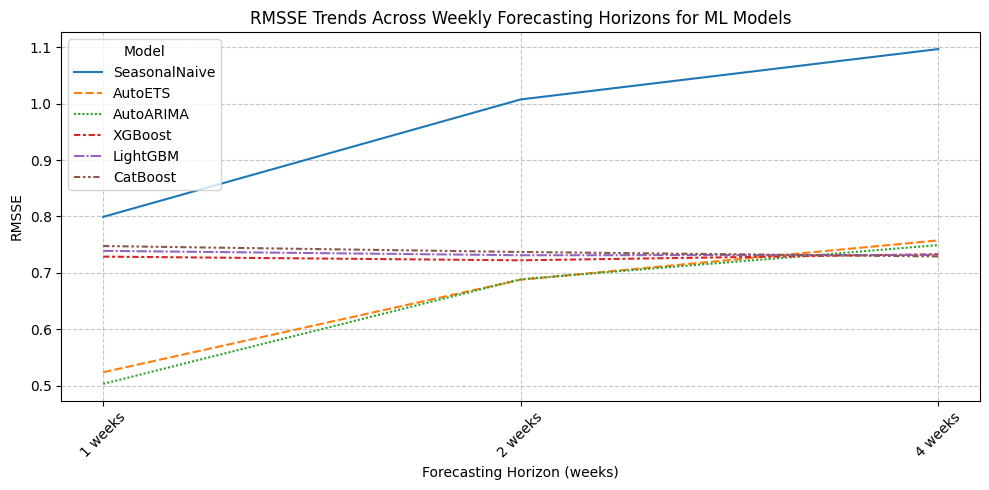

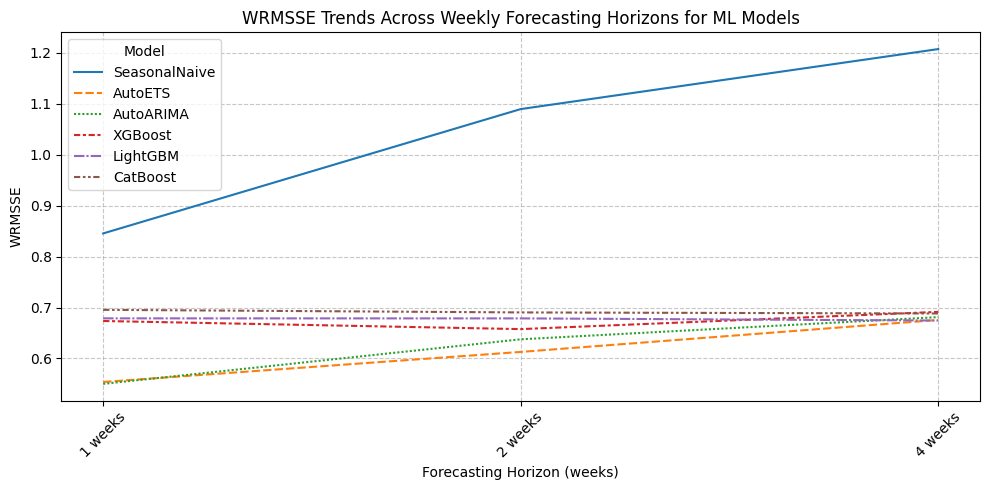

In [ ]:
# Plotting RMSSE Trends for Weekly Models
plt.figure(figsize=(10, 5))
sns.lineplot(data=rmsse_weekly_df)
plt.title('RMSSE Trends Across Weekly Forecasting Horizons for ML Models')
plt.xlabel('Forecasting Horizon (weeks)')
plt.ylabel('RMSSE')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

# Plotting WRMSSE Trends for Weekly Models
plt.figure(figsize=(10, 5))
sns.lineplot(data=wrmsse_weekly_df)
plt.title('WRMSSE Trends Across Weekly Forecasting Horizons for ML Models')
plt.xlabel('Forecasting Horizon (weeks)')
plt.ylabel('WRMSSE')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model')
plt.tight_layout()
plt.show()
